# **Calidad de sueño**

![Calidad de sueño](https://www.nutrimarket.com/blog/wp-content/uploads/2020/07/1-10.jpg)

---
##Introducción
El sueño es un aspecto fundamental de nuestra salud y bienestar. Sin embargo, a pesar de su importancia tendemos a descuidarlo mucho. Los trabajadores reducen sus horas de descanso debido a turnos extras o el estrés que les causa afrontar un nuevo día, los estudiantes descuidamos nuestras horas de sueño debido a la carga académica. Todo esto afecta nuestro rendimiento, salud mental y bienestar general. Por lo tanto, comprender los factores que influyen en la calidad del sueño es esencial para promover hábitos más saludables y mejorar la calidad de nuestra vida.

Nuestro estudio se enfocará en analizar cómo diferentes variables del estilo de vida afectan la calidad y duración del sueño. Buscaremos e identificaremos patrones que nos permitan explicar cómo los hábitos diarios y condición física influyen en el descanso.

Nuestra principal motivación de análisis para estos datos no es solo responder estas preguntas, sino también ganar y/o generar conciencia sobre la importancia de descansar bien y cómo mejorar nuestros hábitos para lograr una buena salud del sueño.






##Integrantes

*   Axel Tapia 202373080-7, 21.707.276-K.
*   Benjamin Cegarra 202373006-8, 21.727.272-6
*   Martín Espinoza 202373119-6, 21.769.181-8
*   Samira Estay, 202373085-8, 21.626.556-4.




Harémos un análisis de los datos recogidos de un dataset acerca de la calidad del sueño según la calidad de vida de la persona, teniendo varias variables de distinto tipo que nos sirven para estudiar cómo se relacionan entre sí.
Las variables que participan en este data set son:


*   Persona
*   Sexo
*   Edad
*   Ocupación
*   Duración del sueño
*   Cálidad del sueño
*   Actividad física
*   Nivel de estrés
*   IMC
*   Presión sanguinea
*   Freacuencia cardiaca
*   Pasos diarios
*   Trastorno del sueño

A partir de ellas se hará el analisis para responder las preguntas planteadas.





##Limpieza de datos
Cómo primer paso para llegar al análisis de nuestras variables, debemos limpiar la dataset que contiene estos datos, ya que, dentro de esta podemos encontrar valores nulos o 'outliers' que son valores que són átipicos y que pueden afectar los resultados de nuestros gráficos o análisis posterior.

Para esto primero abriremos nuestro archivo que contiene la dataset con el siguiente código en Python:

In [ ]:
#Código que monta la base de datos guardada en el drive para no tener que subirla cáda vez que se inicie sesión.
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/datasets/Sleep_health_and_lifestyle_dataset.csv")

Mounted at /content/drive


Luego de abrir la dataset, vemos si existen datos vacíos imprimiendo la cantidad de datos vacíos encontrados en cada columna.

In [ ]:
print(df.isnull().sum())

Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
dtype: int64


Sabiendo que solo existen datos vacíos en la columna de "Trastornos del sueño", podemos notar que se refiere a que la persona en cuestión no posee ningún trastorno, y son la mayoría de personas en el dataset, por lo que son datos que a pesar de ser vacíos, sí indicán un valor, por lo que son de nuestro interés.

Entonces lo que se hará es reemplazar este valor nulo, por algún valor string que indique que la persona no posee ningún trastorno asociado al sueño.

Con el siguiente código reemplazamos estos valores nulos por el string "Don't Have" indicando que la persona no tiene ningún trastorno.

In [ ]:
df.fillna({"Sleep Disorder": "Don't Have"}, inplace=True)
#Cambié el valor NaN de Sleep Disorder a Dont' Have, pq siento que igual es un dato importante si tiene o no algun trastorno del sueño
df["BMI Category"] = df["BMI Category"].replace({"Normal Weight": "Normal"})#Cambié el valor de Normal Weight por Normal
print(df.isnull().sum())

Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64


Luego de tratar con los valores vacíos, se debe tratar con los datos outliers, es decir con los datos atípicos. Siendo estos los que llegan a extremos muy altos o muy bajos, por lo pueden afectar en cuanto a nuestro análisis y gráfcos.

Para esto, con el cálculo de los cuartiles y índice intercuartilico podemos saber cuáles datos salen de este rango, siendo estos nuestros datos outliers.
Entonces, primero se cálcula el cuartíl uno y el cuartíl tres y sácamos su diferencia, obteniendo el IQR por cada columna con datos cuantitativos. Ya con este valor se cálcula el rango límite inferior y el rango límite superior de cada columna.

Posteriormente, con el conocimiento de los límites, analizamos por cada columna, qué datos quedan fuera de estos límites y notando los outliers.

In [ ]:
df_numerico = df.select_dtypes(include=['number'])

#Función para detectar si existen outliers en las columnas con datos cuantitativos
def detectar_outliers(df):

  outliers_dict = {}
  for columna in df.columns:
    if columna != "Person ID" and columna != "Age":
      Q1 = df[columna].quantile(0.25)
      Q3 = df[columna].quantile(0.75)
      IQR = Q3 - Q1
      limite_inferior = Q1 - 1.5 * IQR
      limite_superior = Q3 + 1.5 * IQR

      outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]
      outliers_dict[columna] = len(outliers)

      print(f"\n {columna}:")
      print(f"  - Q1 (25%): {Q1}")
      print(f"  - Q3 (75%): {Q3}")
      print(f"  - IQR: {IQR}")
      print(f"  - Umbral Inferior: {limite_inferior}")
      print(f"  - Umbral Superior: {limite_superior}")
      print(f"  - Outliers detectados: {len(outliers)}")


  return outliers_dict

outliers_encontrados = detectar_outliers(df_numerico)


 Sleep Duration:
  - Q1 (25%): 6.4
  - Q3 (75%): 7.8
  - IQR: 1.3999999999999995
  - Umbral Inferior: 4.300000000000001
  - Umbral Superior: 9.899999999999999
  - Outliers detectados: 0

 Quality of Sleep:
  - Q1 (25%): 6.0
  - Q3 (75%): 8.0
  - IQR: 2.0
  - Umbral Inferior: 3.0
  - Umbral Superior: 11.0
  - Outliers detectados: 0

 Physical Activity Level:
  - Q1 (25%): 45.0
  - Q3 (75%): 75.0
  - IQR: 30.0
  - Umbral Inferior: 0.0
  - Umbral Superior: 120.0
  - Outliers detectados: 0

 Stress Level:
  - Q1 (25%): 4.0
  - Q3 (75%): 7.0
  - IQR: 3.0
  - Umbral Inferior: -0.5
  - Umbral Superior: 11.5
  - Outliers detectados: 0

 Heart Rate:
  - Q1 (25%): 68.0
  - Q3 (75%): 72.0
  - IQR: 4.0
  - Umbral Inferior: 62.0
  - Umbral Superior: 78.0
  - Outliers detectados: 15

 Daily Steps:
  - Q1 (25%): 5600.0
  - Q3 (75%): 8000.0
  - IQR: 2400.0
  - Umbral Inferior: 2000.0
  - Umbral Superior: 11600.0
  - Outliers detectados: 0


Con esto se pudo detectar que en la columna "Heart Rate" existen 15 datos que son outliers, por lo que no son de nuestro interés. Entonces vamos a sacar estos datos de nuestra dataset con el siguiente código:

In [ ]:
#Código que limpia las columnas con outliers y guarda el dataset en una copia sin estos datos
df_clean = df.copy()
for columna in df_numerico.columns:
  Q1 = df_numerico[columna].quantile(0.25)
  Q3 = df_numerico[columna].quantile(0.75)
  IQR = Q3 - Q1
  limite_inferior = Q1 - 1.5 * IQR
  limite_superior = Q3 + 1.5 * IQR

  df_clean = df_clean[(df_clean[columna] >= limite_inferior) & (df_clean[columna] <= limite_superior)]

df_clean.to_csv("dataset_clean.csv", index=False)
print("\n Dataset limpio guardado como 'dataset_clean.csv'")


 Dataset limpio guardado como 'dataset_clean.csv'


De esta manera limpiamos la dataset y la guardamos en nuevo archivo llamado "dataset_clean.csv", en donde ahora sí solo tenemos los datos que son relevantes y aportan en el posterior análisis.

##Análisis de datos

Luego de hacer una limpieza optima de la dataset y teniendo los datos que son de utilidad, se puede empezar el análisis de estos datos. Para comenzar el análsis dispondremos de distintos tipos de gráficos que nos entregarán información relevante de estos, viendo como se relacionan entre sí y como se distribuyen.

In [ ]:
def nombresEnEje(eje,total):

    for columna in eje.patches:
        altura = columna.get_height() #guarda la altura de las columnas
        if altura > 0:
            x = columna.get_x() + columna.get_width() / 2 # calcula la mitad de cada columna
            porcentaje = (altura / total) * 100 #calcula el porcentaje
            eje.text(x, altura, f"{int(altura)}\n{porcentaje:.1f}%", ha='center', va='bottom', fontsize=8) #imprime la cantidad y el porcentaje de personas por columna

In [ ]:
def mostrarCaracts(titulo, ejex):
    plt.title(titulo) #coloca el nombre del título
    plt.xlabel(ejex) #coloca el nombre del eje x
    plt.ylabel("Cantidad de personas") #coloca el nombre del eje y
    plt.tight_layout() # Ajusta el leyout para que no se corten etiquetas
    plt.show()

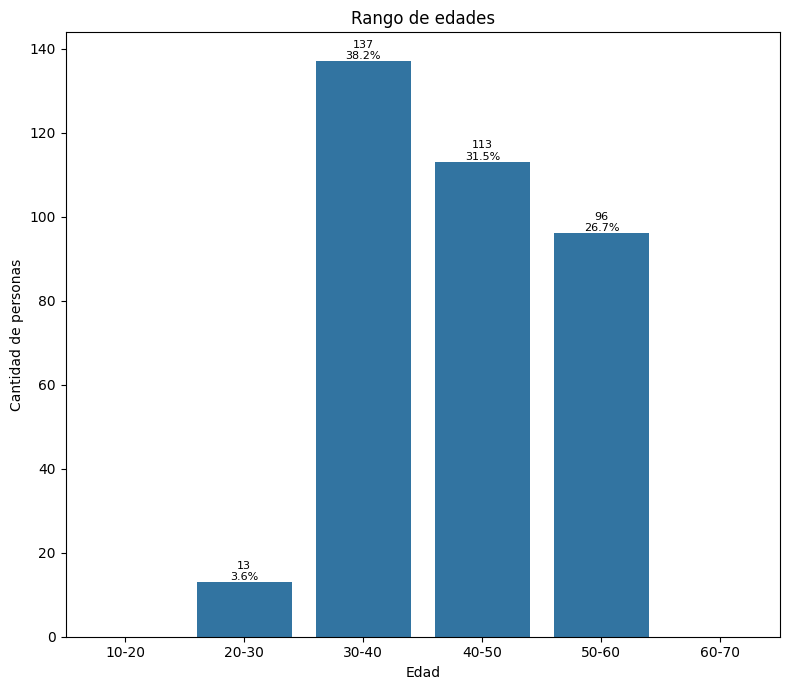

In [ ]:
#Gráfico que ve la cantidad de persona en un rango de edad
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset_clean.csv")
plt.figure(figsize=(8, 7))

df["Edad"] = pd.cut(df["Age"],bins=[10, 20, 30, 40, 50, 60, float("inf")],labels=["10-20", "20-30", "30-40", "40-50", "50-60", "60-70"],right=False) # agrupamos por edad

total = df["Edad"].count()#total de personas

# Crear el gráfico con countplot
ejes = sns.countplot(data=df, x="Edad")


nombresEnEje(ejes, total) #Funcion antes creada
mostrarCaracts("Rango de edades", "Edad") #Funcion antes creada

Como se aprecia en este gráfico, la mayor cantidad de personas pertenece a un rango de 30 entre 40 años de edad.

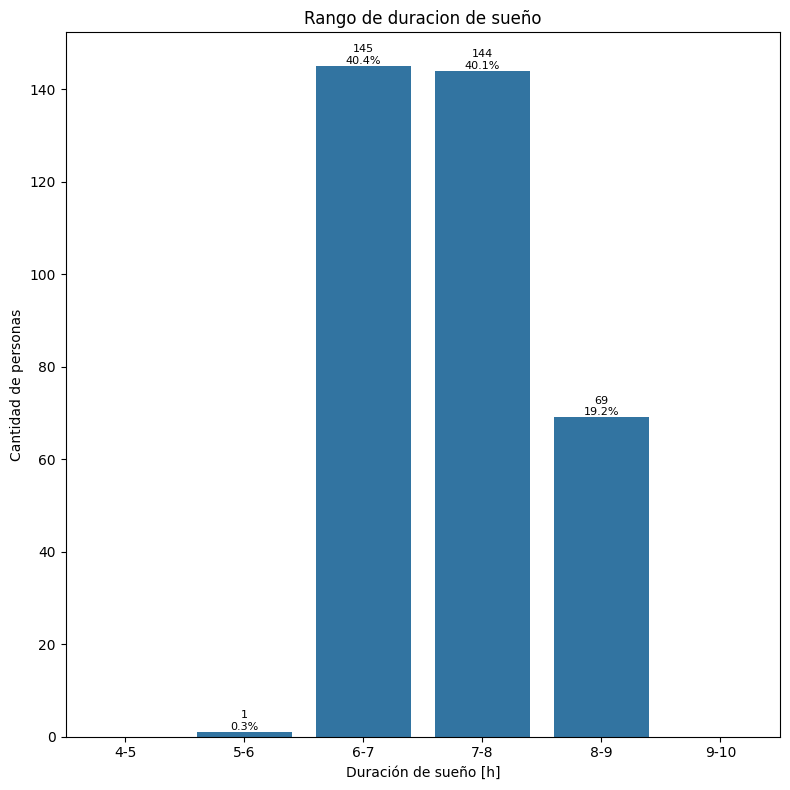

In [ ]:
#Gráfico para ver la cantidad de personas que hay en un rango de duración del sueño
df = pd.read_csv("dataset_clean.csv")
plt.figure(figsize=(8, 8))

df["Sleep Duration"] = pd.cut(df["Sleep Duration"],bins=[4, 5, 6, 7, 8, 9, float("inf")],labels=["4-5","5-6", "6-7", "7-8", "8-9", "9-10"],right=False)

total = df["Sleep Duration"].count()# Total de personas válidas

ejes = sns.countplot(data=df, x="Sleep Duration")# Crear el gráfico con countplot

nombresEnEje(ejes, total) #Funcion antes creada
mostrarCaracts("Rango de duracion de sueño", "Duración de sueño [h]") #Funcion antes creada

Las horas de sueño predominantes son entre 6-7 horas, seguido de 7-8 horas.

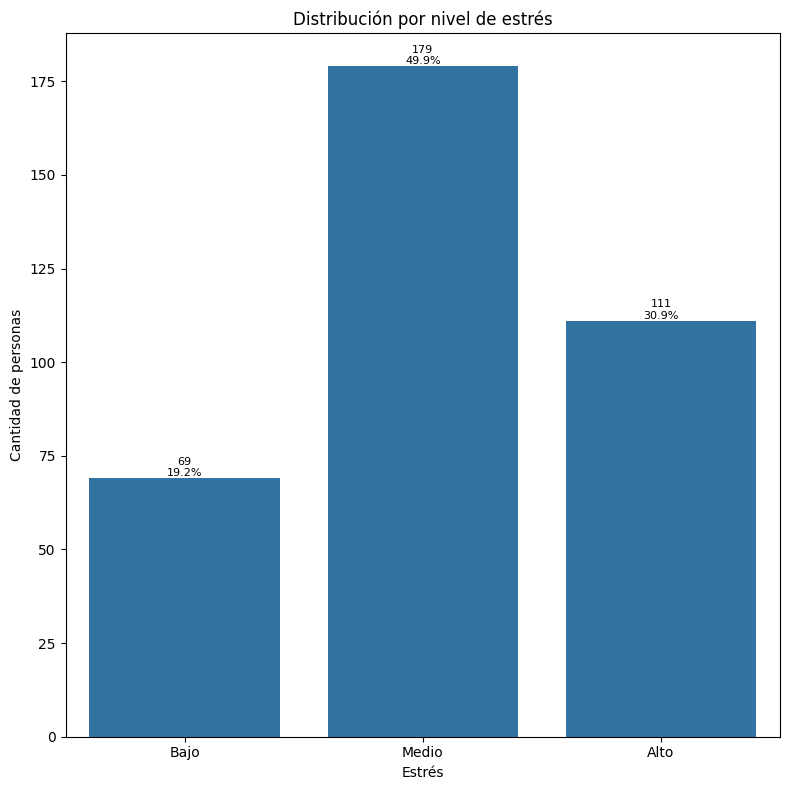

En el dataset, los niveles de estres van del 0-10, y los niveles normales de estres van desde bajo hasta alto


In [ ]:
#Gráfico de nivel de estres, lo separé en 3, ya que los niveles de estres van de bajo a alto y en el dataset nosotros lo tenemos de 1-8
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 8)) #Cambia el tamaño del gráfico

#bins = columnas, labels = nombres de columnas
df["Nivel de Estrés"] = pd.cut(df["Stress Level"], bins=[0, 3, 6, float('inf')], labels=["Bajo", "Medio", "Alto"], right=True) #Separamos la columna Stress Level Level en 3, bajo, medio y alto

total = df["Nivel de Estrés"].count()#cantidad total de personas

ejes = sns.countplot(data=df, x="Nivel de Estrés")#Crea el gráfico de barras con la libreria seaborn

nombresEnEje(ejes,total)

mostrarCaracts("Distribución por nivel de estrés", "Estrés")

print("En el dataset, los niveles de estres van del 0-10, y los niveles normales de estres van desde bajo hasta alto")

Por otra parte, el estrés medio predomina en nuestra muestra, seguido del alto y por último el bajo.

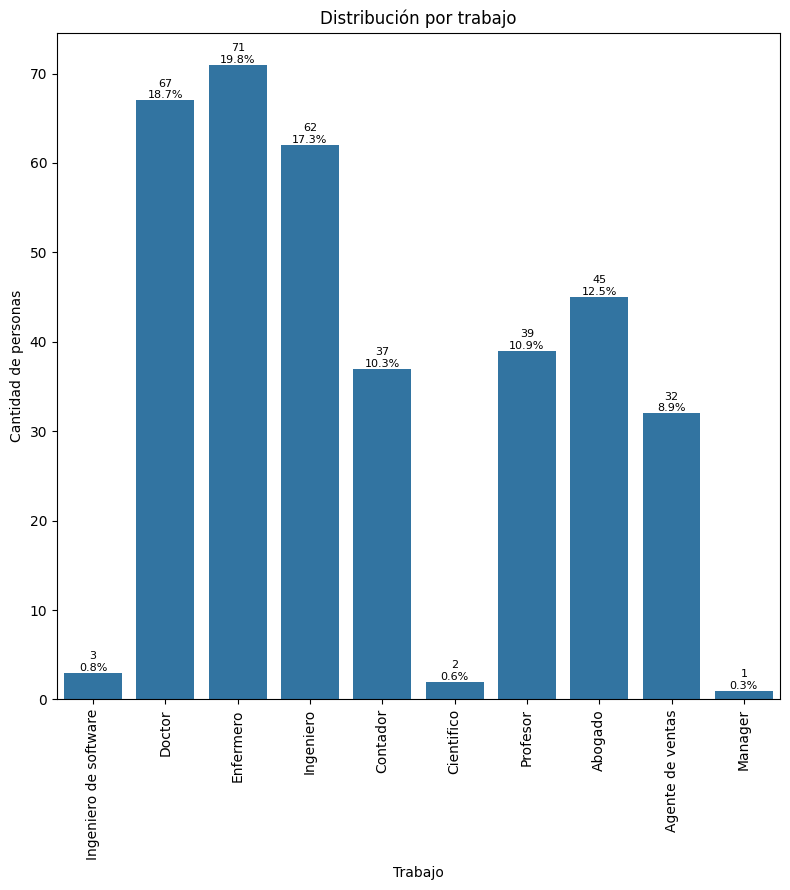

In [ ]:
#Gráfico de cantidad de personas por ocupación
df = pd.read_csv("dataset_clean.csv")
df["Occupation"] = df["Occupation"].replace({"Software Engineer": "Ingeniero de software", 'Nurse': "Enfermero", 'Engineer': 'Ingeniero', 'Accountant': 'Contador', 'Scientist': 'Cientifico', 'Teacher': 'Profesor', 'Lawyer': 'Abogado', 'Salesperson': 'Agente de ventas'})#Le cambio los nombres a las opciones de la columna

total = df["Occupation"].count()

plt.figure(figsize=(8, 9)) #Cambia el tamaño del gráfico
ejes = sns.countplot(data=df, x="Occupation") #Crea el gráfico de barras con la libreria seaborn

nombresEnEje(ejes,total)


plt.xticks(rotation=90)  # Rota las etiquetas del eje x para mejor lectura

mostrarCaracts("Distribución por trabajo", "Trabajo")

Gráfico para analizar la distribución de trabajos a los que pertenecen las personas de la muestra.

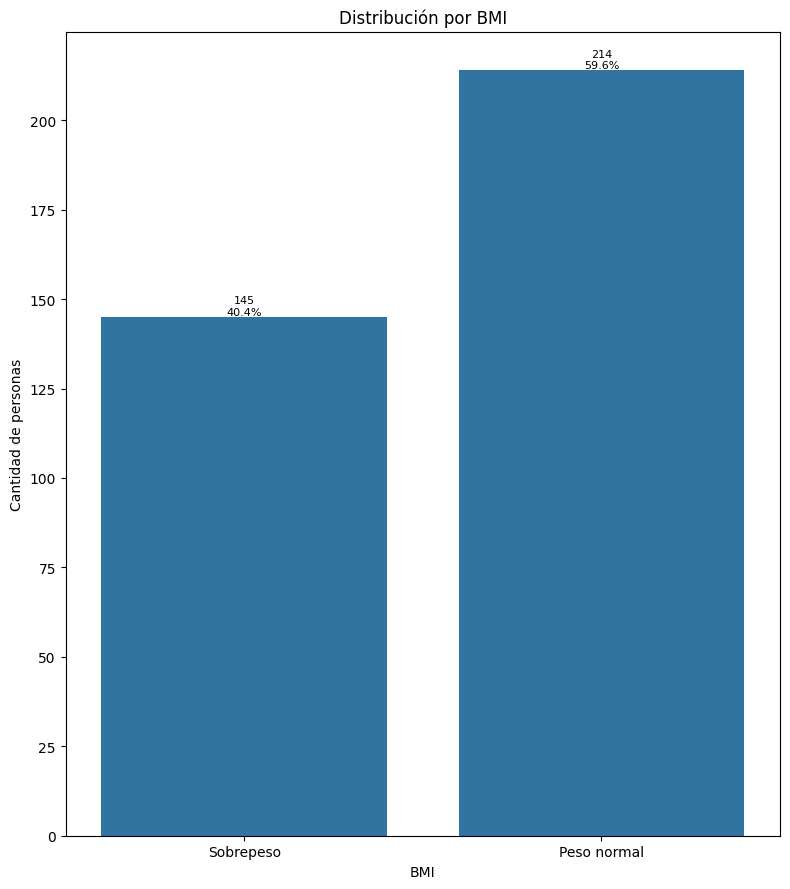

In [ ]:
#Gráfico de cantidad de personas dependiendo su BMI
df = pd.read_csv("dataset_clean.csv")
df["BMI Category"] = df["BMI Category"].replace({'Normal': 'Peso normal', 'Normal Weight': 'Peso normal', 'Overweight': 'Sobrepeso'}) #Le cambio los nombres a las opciones de la columna

total = df["BMI Category"].count()

plt.figure(figsize=(8, 9)) #Cambia el tamaño del gráfico
ejes = sns.countplot(data=df, x="BMI Category") #crea el grafico de barras con la libreria seaborn

nombresEnEje(ejes, total)

mostrarCaracts("Distribución por BMI", "BMI")

Gráfico de la distribución del IMC en la población de la muestra.

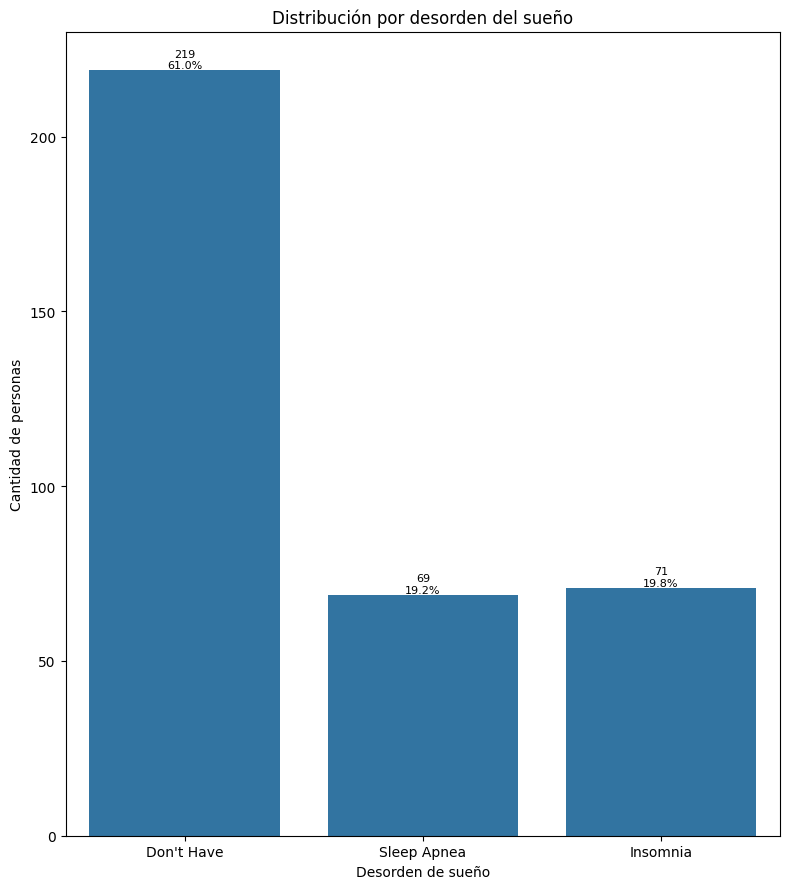

In [ ]:
#Gráfico de cantidad de personas dependiendo de su desorden de sueño
df = pd.read_csv("dataset_clean.csv")

total = df["Sleep Disorder"].count()

plt.figure(figsize=(8, 9))
ejes = sns.countplot(data=df, x="Sleep Disorder")

nombresEnEje(ejes, total)

mostrarCaracts("Distribución por desorden del sueño", "Desorden de sueño")

Gráfico de la distribución de personas que presentan trastornos del sueño en la muestra.

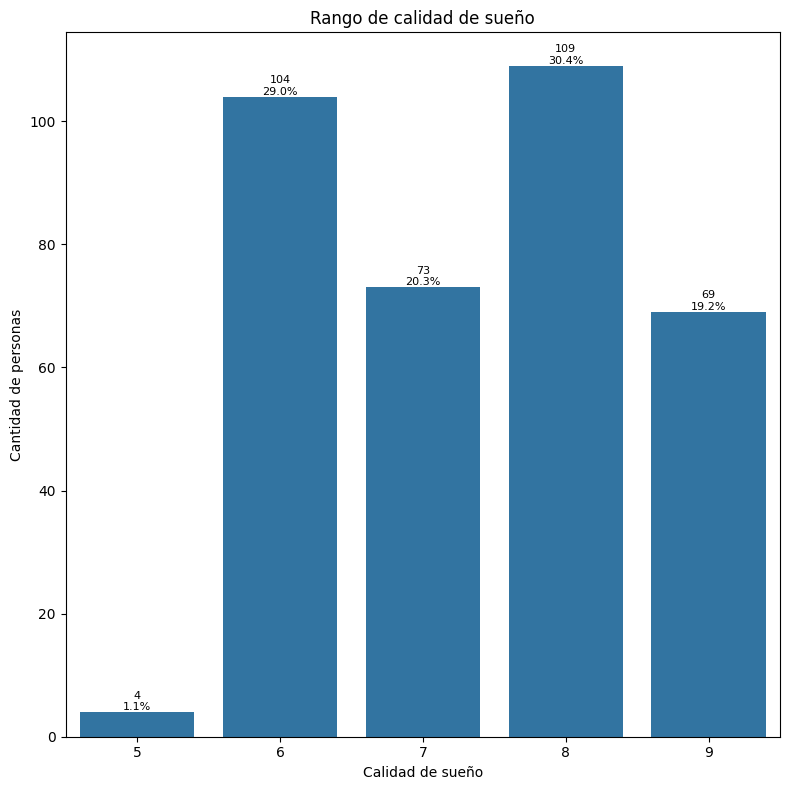

In [ ]:
df = pd.read_csv("dataset_clean.csv")

total = df["Quality of Sleep"].count()  # Contiene el total de personas

plt.figure(figsize=(8, 8))  # Tamaño del gráfico
eje = sns.countplot(data=df, x="Quality of Sleep")  # Creamos el grafico

nombresEnEje(eje, total)  # Funcion ya creada
mostrarCaracts("Rango de calidad de sueño", "Calidad de sueño")  # Funcion ya creada


Nuestro dataset va desde 0-100 en nivel de actividad fisica, por lo que los separamos en 4 secciones, sedentario, actividad ligera, 
 actividad moderada y muy activo, cada uno correspondiendo a un 25%


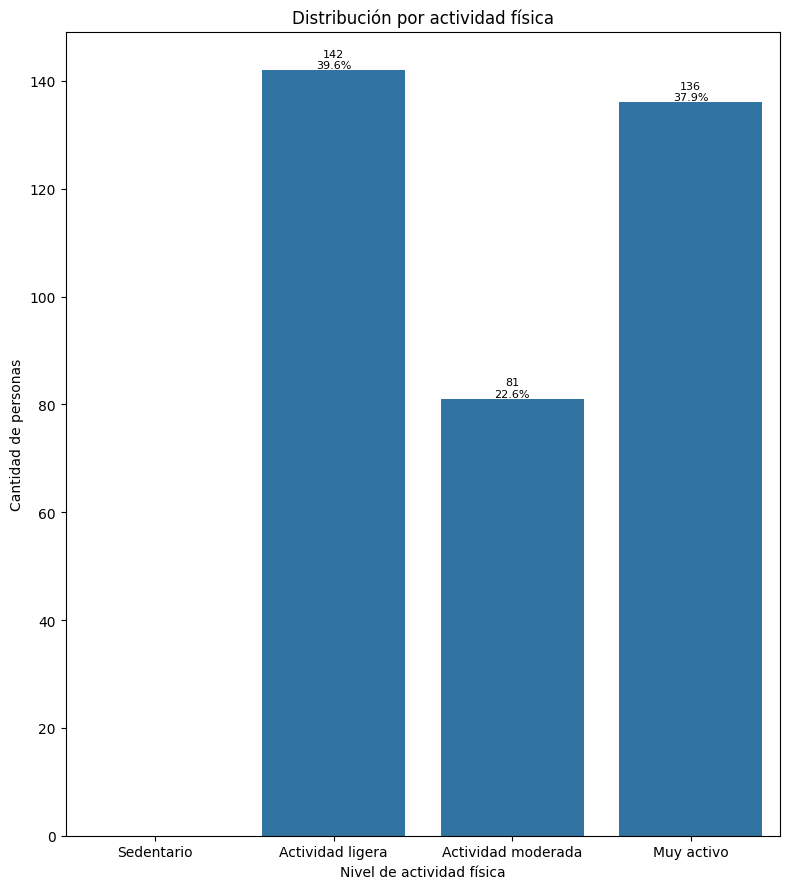

In [ ]:
#Gráfico de cantidad de personas dependiendo de su cantidad de actividad física
print("Nuestro dataset va desde 0-100 en nivel de actividad fisica, por lo que los separamos en 4 secciones, sedentario, actividad ligera, \n actividad moderada y muy activo, cada uno correspondiendo a un 25%")
df = pd.read_csv("dataset_clean.csv")
df["Nivel de Actividad"] = pd.cut(df["Physical Activity Level"],bins=[0, 25, 50, 75, float("inf")],labels=["Sedentario", "Actividad ligera", "Actividad moderada", "Muy activo"],right=False) #se tomaron todos los datos de la cantidad de actividad fisica y se dividieron en 4

total = df["Nivel de Actividad"].count()

plt.figure(figsize=(8, 9)) #Cambia el tamaño del gráfico
ejes = sns.countplot(data=df, x="Nivel de Actividad") #crea el grafico de barras con la libreria seaborn

nombresEnEje(ejes, total)

mostrarCaracts("Distribución por actividad física", "Nivel de actividad física")

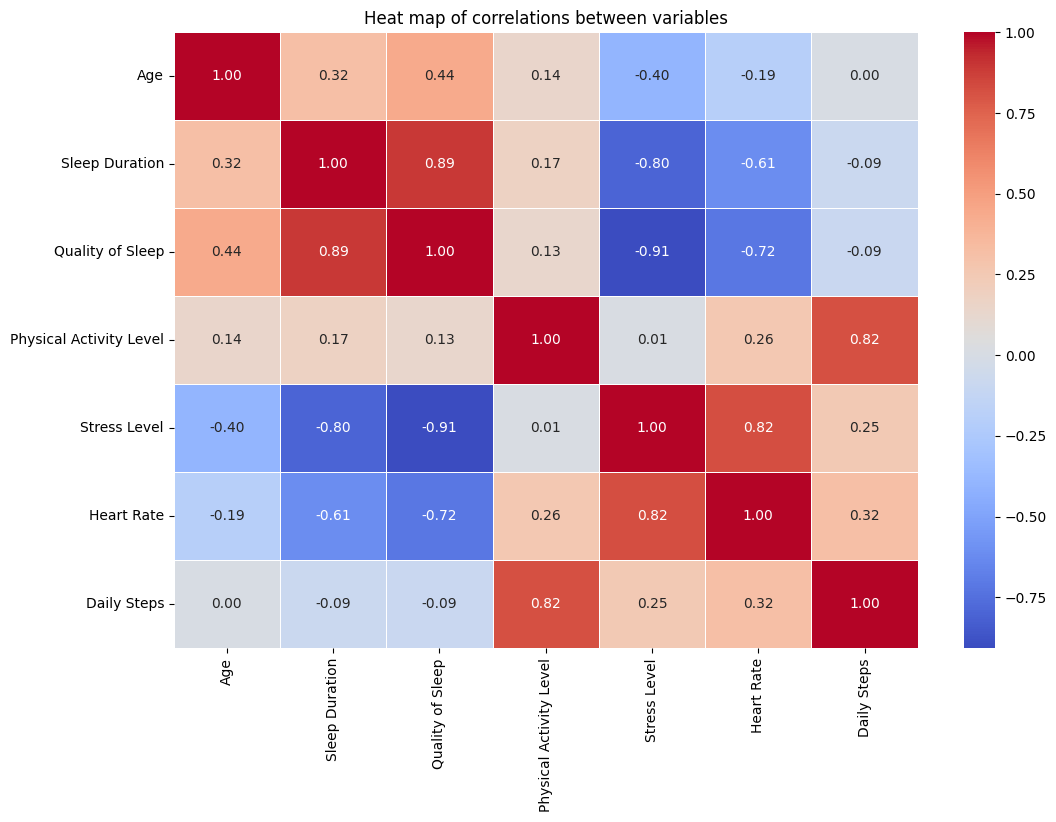

In [ ]:
#ESTE MAPA ES SOLO ENTRE VARIABLES CUANTITATIVAS
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_clean.csv")
df_numerico = df.select_dtypes(include=['number']).drop(columns=["Person ID"], errors='ignore')

#Calcular la matriz de correlación
correlacion = df_numerico.corr()

#Crear mapa de calor
plt.figure(figsize=(12, 8))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", linewidths=0.5, fmt=".2f")

plt.title("Heat map of correlations between variables")
plt.show()

Luego de visualizar de manera general el dataset, generamos un mapa de calor para encontrar una relación entre las variables y así poder estudiarlas.

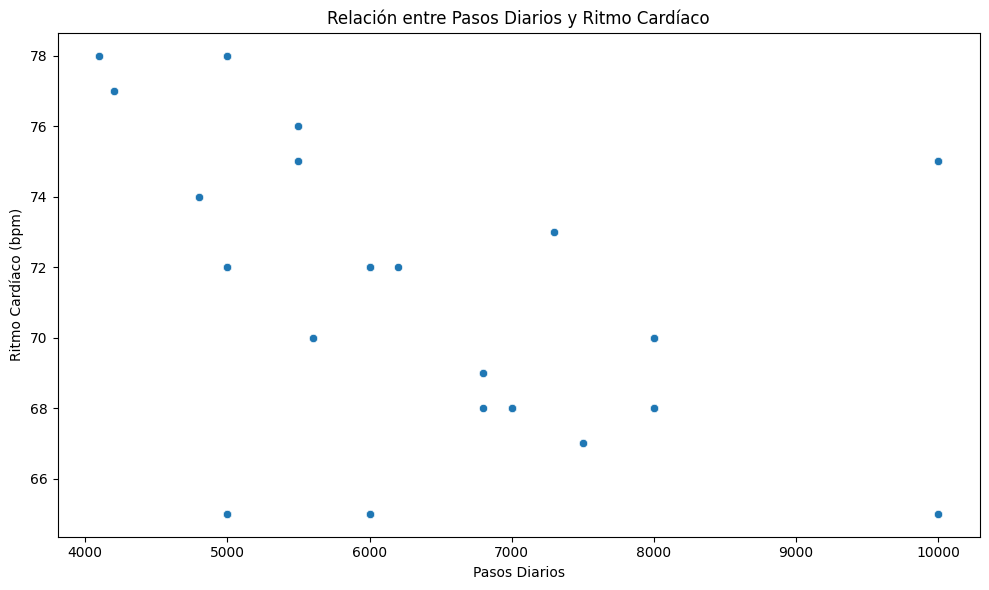

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x="Daily Steps", y="Heart Rate", data=df)
plt.title("Relación entre Pasos Diarios y Ritmo Cardíaco")
plt.xlabel("Pasos Diarios")
plt.ylabel("Ritmo Cardíaco (bpm)")
plt.tight_layout()
plt.show()

Gráfico que relaciona la cantidad de pasos diarios con el ritmo cardiaco. En donde podemos apreciar que a mayor cantidad de pasos diarios, el ritmo cardiaco de las personas va disminuyendo.

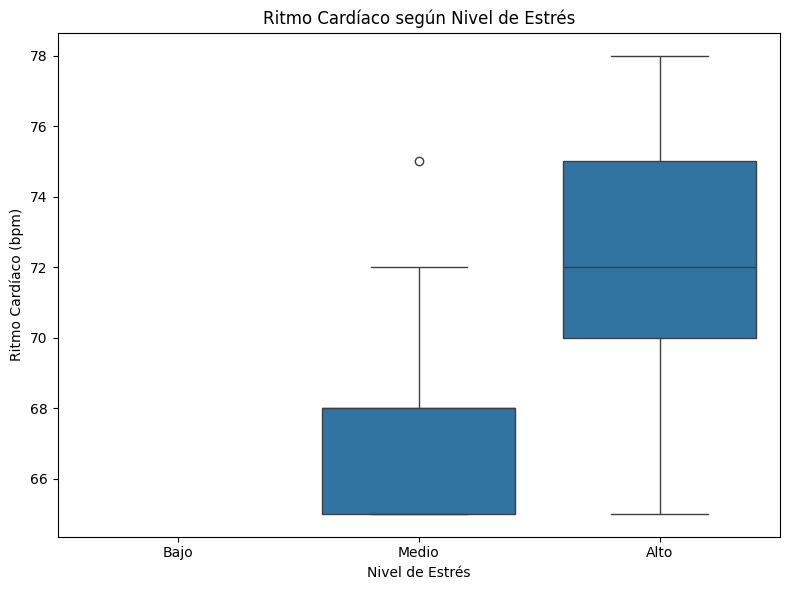

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def clasificar_estres(nivel): #Función que clasifica el nivel de estrés
    if nivel < 3:
        return "Bajo"
    elif nivel < 6:
        return "Medio"
    else:
        return "Alto"

df["Stress Category"] = df["Stress Level"].apply(clasificar_estres)
plt.figure(figsize=(8, 6))
sns.boxplot(x="Stress Category", y="Heart Rate", data=df, order=["Bajo", "Medio", "Alto"])
plt.title("Ritmo Cardíaco según Nivel de Estrés")
plt.xlabel("Nivel de Estrés")
plt.ylabel("Ritmo Cardíaco (bpm)")
plt.tight_layout()
plt.show()


Gráfico que nos muestra la relación entre el nivel de estrés de las personas y su ritmo cárdiaco. Se puede apreciar que en las personas que presentan un nivel de estrés alto, tienden a tener un ritmo cardiaco alto también.

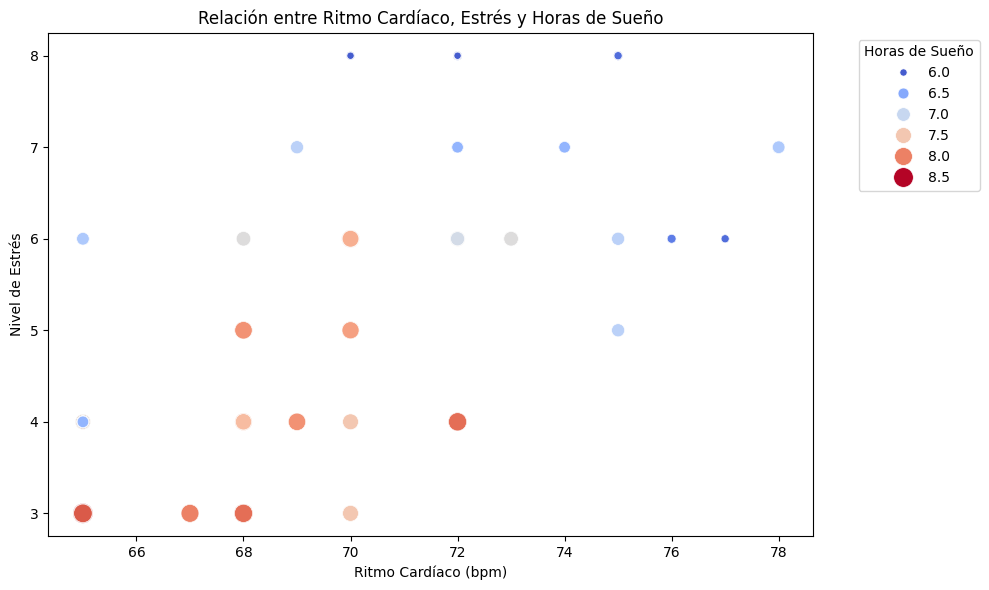

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Heart Rate",
    y="Stress Level",
    size="Sleep Duration",  # tamaño del punto = horas de sueño
    hue="Sleep Duration",   # color del punto = horas de sueño
    palette="coolwarm",
    sizes=(20, 200),
    data=df
)
plt.title("Relación entre Ritmo Cardíaco, Estrés y Horas de Sueño")
plt.xlabel("Ritmo Cardíaco (bpm)")
plt.ylabel("Nivel de Estrés")
plt.legend(title="Horas de Sueño", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


En este gráfico, podemos ver la relación entre tres variables, siendo el ritmo cardiaco, el nievel de estrés y las horas de sueño de las personas. En donde se puede observer que las personas con menos horas de sueño, en su mayoría presentan altos niveles de estrés y frecuencias cárdiacas que van desde los 72bpm hasta los 78bpm. Por lo que se puede establecer una relación entre estas tres variables.

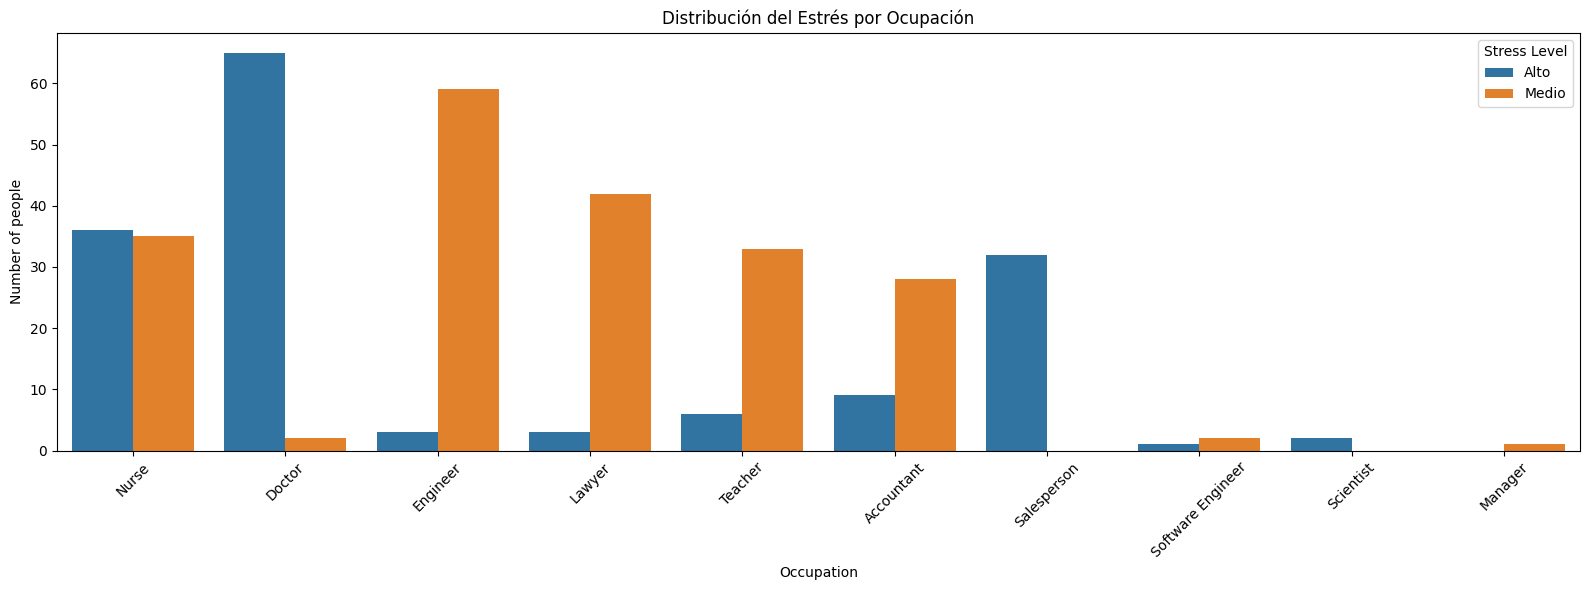

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def clasificar_estres(nivel): #Función que clasifica el nivel de estrés
    if nivel < 3:
        return "Bajo"
    elif nivel < 6:
        return "Medio"
    else:
        return "Alto"

df["Stress Category"] = df["Stress Level"].apply(clasificar_estres)

plt.figure(figsize=(16, 6))
sns.countplot(x="Occupation", hue="Stress Category", data=df, order=df["Occupation"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Distribución del Estrés por Ocupación")
plt.xlabel("Occupation")
plt.ylabel("Number of people")
plt.legend(title="Stress Level")
plt.tight_layout()
plt.show()

El gráfico de estrés por ocupación muestra que trabajos tienden a tener niveles de estrés más altos. Esto nos da una pista de que el tipo de trabajo tiene un impacto significativo en los niveles de estrés, lo cual puede afectar la calidad del sueño.

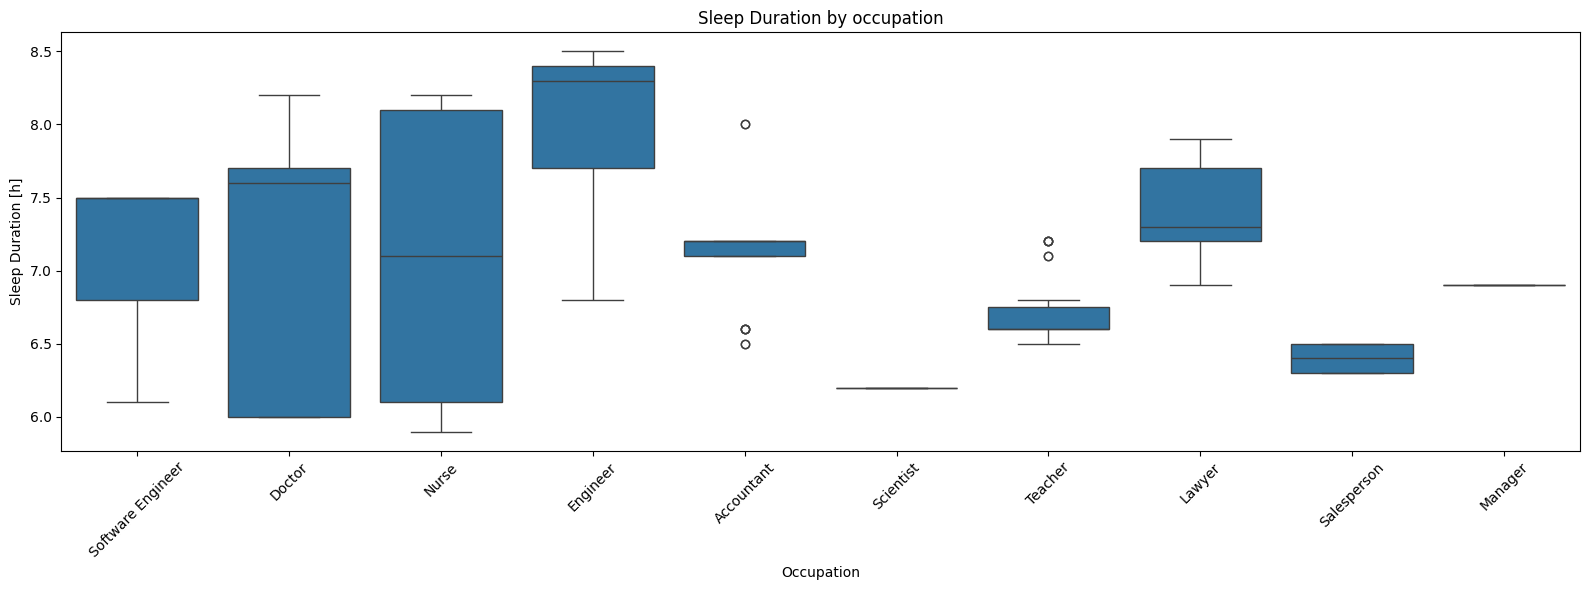

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))  # Cambia el tamaño del gráfico (ancho x alto)
sns.boxplot(x=df["Occupation"], y=df["Sleep Duration"])
plt.xticks(rotation=45)  # Rota las etiquetas del eje x para mejor lectura
plt.title("Sleep Duration by occupation")
plt.xlabel("Occupation")
plt.ylabel("Sleep Duration [h]")
plt.tight_layout()  # Ajusta el layout para que no se corten etiquetas
plt.show()

El gráfico que vemos de duración del sueño según ocupación, nos muestra que las personas con trabajos más "sedentarios" o de oficina tienden a dormir más horas que aquellas con trabajos de turno o que requieren de mayor esfuerzo físico. Esto probablemente debe estar relacionado con los horarios más flexibles de algunos trabajos en comparación con aquellos que funcionan por turnos.

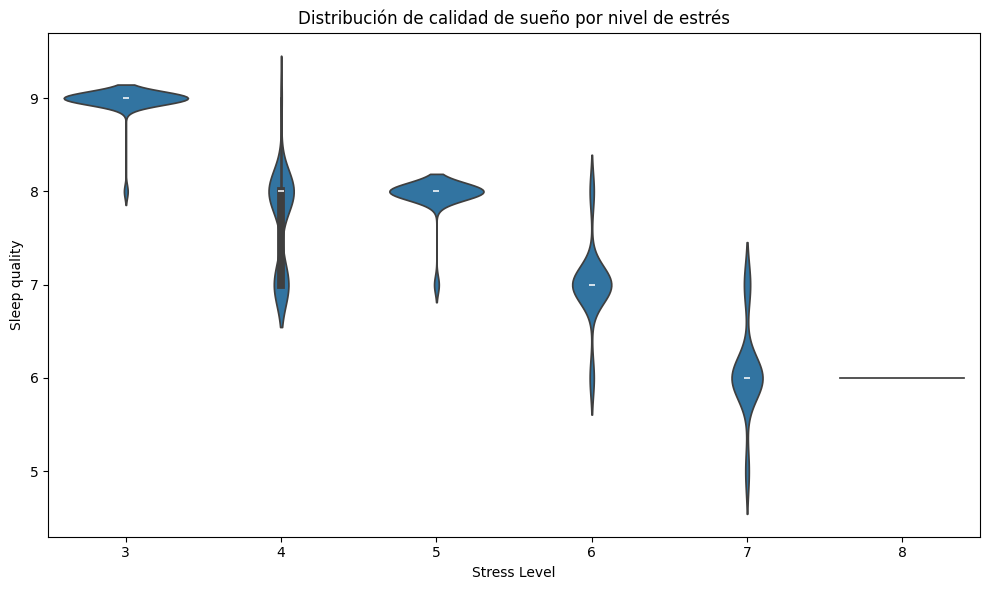

In [ ]:
#Gráfico estres vs calidad de sueño con grafico de violin
df = pd.read_csv("dataset_clean.csv")
plt.figure(figsize=(10, 6))
sns.violinplot(x="Stress Level", y="Quality of Sleep", data=df, inner="box") #genera el grafico de violin entre los niveles de estres y la calidad del sueño para ver donde hay mas datos
plt.title("Distribución de calidad de sueño por nivel de estrés")
plt.xlabel("Stress Level")
plt.ylabel("Sleep quality")
plt.tight_layout()
plt.show()


Este gráfico de violin compara el estrés y calidad del sueño. Analizándolo podemos darnos cuenta de que nos muestra claramente que a mayores niveles de estrés, la calidad del sueño disminuye. Esto confirma la relación negativa (-0.91) entre estrés y sueño que observamos en el mapa de calor.

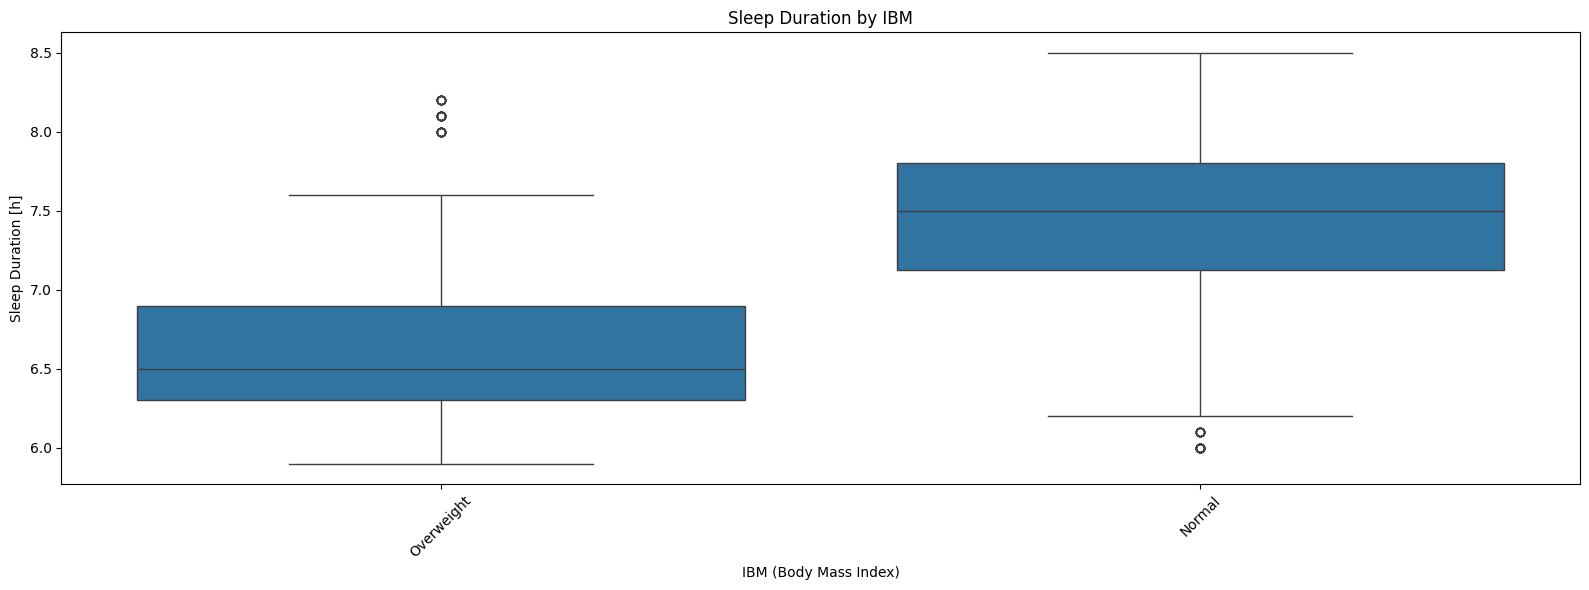

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))  # Cambia el tamaño del gráfico (ancho x alto)
sns.boxplot(x=df["BMI Category"], y=df["Sleep Duration"])
plt.xticks(rotation=45)  # Rota las etiquetas del eje x para mejor lectura
plt.title("Sleep Duration by IBM")
plt.xlabel("IBM (Body Mass Index)")
plt.ylabel("Sleep Duration [h]")
plt.tight_layout()  # Ajusta el layout para que no se corten etiquetas
plt.show()

El análisis de BMI, o IMC (índice de masa corporal) contra duración del sueño muestra que las personas con sobrepeso u obesidad tienden a tener una duración más corta en la duración de este, versus las personas con un IMC normal.

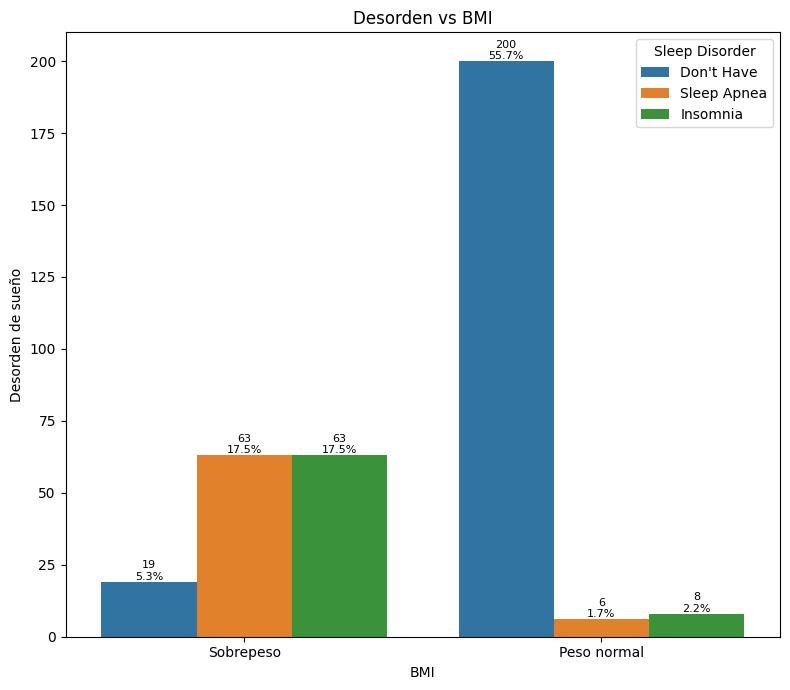

In [ ]:
#Gráfico de BMI contra desorden de sueño
plt.figure(figsize=(8, 7))
df["BMI Category"] = df["BMI Category"].replace({'Normal': 'Peso normal', 'Normal Weight': 'Peso normal', 'Overweight': 'Sobrepeso'})
eje = sns.countplot(x="BMI Category", hue="Sleep Disorder", data=df)
total = total = df["BMI Category"].count()

nombresEnEje(eje, total)

plt.title("Desorden vs BMI")
plt.xlabel("BMI")
plt.ylabel("Desorden de sueño")
plt.tight_layout()
plt.show()

El análisis de IMC contra desordenes del sueño muestra que las personas con sobrepeso u obesidad tienen una tendencia más alta a padecer estas enfermedades. Como se puede observar, la mayoría de los casos se concentran en ese intervalo. Por otro lado, las personas con un IMC normal demuestran en la mayoría que no poseen un desorden del sueño. Por lo que podemos distinguir que un IMC de sobrepeso implicaría un sueño menos sano.

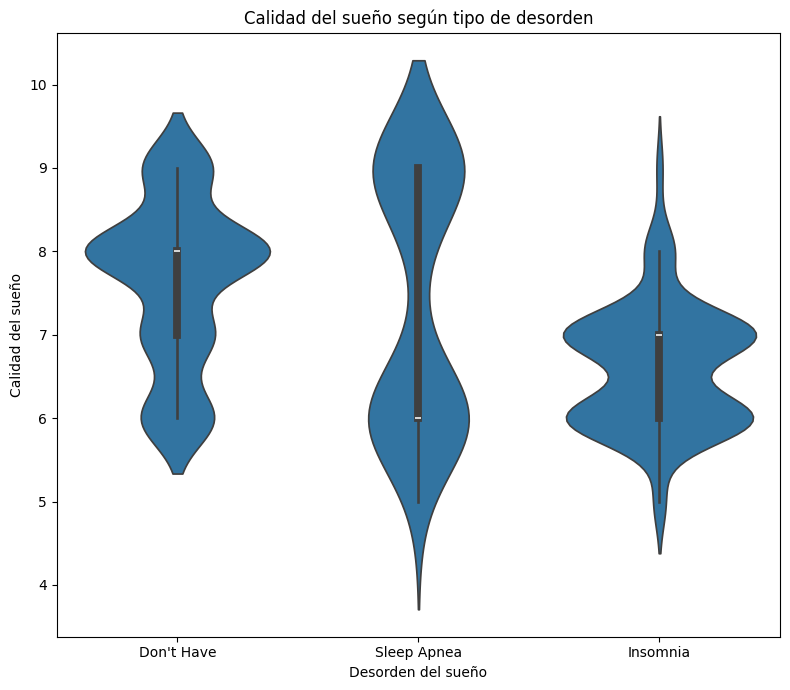

In [ ]:
# Gráfico de calidad del sueño según desorden
df = pd.read_csv("dataset_clean.csv")

plt.figure(figsize=(8, 7))
eje = sns.violinplot(x="Sleep Disorder", y="Quality of Sleep", data=df, inner="box")

total = df["Quality of Sleep"].count()  # total de datos considerados

plt.title("Calidad del sueño según tipo de desorden")
plt.xlabel("Desorden del sueño")
plt.ylabel("Calidad del sueño")
plt.tight_layout()
plt.show()


Las personas que no tienen trastornos del sueño tienen una distribución de calidad de sueño que en su mayoría se encuentra en rangos altos (cerca de 8-10).

La distribución es relativamente estrecha, lo que indica que las personas sin trastornos duermen por lo general, bien, con pocas variaciones en la calidad del sueño.

No podemos decir lo mismo de quienes poseen apnea del sueño. Tienen una calidad de sueño considerablemente más baja, con una distribución amplia, por lo que la apnea afecta de manera significativa la calidad del sueño de quienes la padecen.

Las personas con insomnio también tienen una calidad de sueño baja, pero la variabilidad es menor que la de los que poseen apnea del sueño, lo que indica que el insomnio, aunque afecta el sueño, tiene una menor variabilidad en comparación con la apnea.



/tmp/ipython-input-29-274220647.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ejes = sns.violinplot(data=df, y="Stress Level", x="Sleep Duration", inner="box", legend=False, palette="muted")


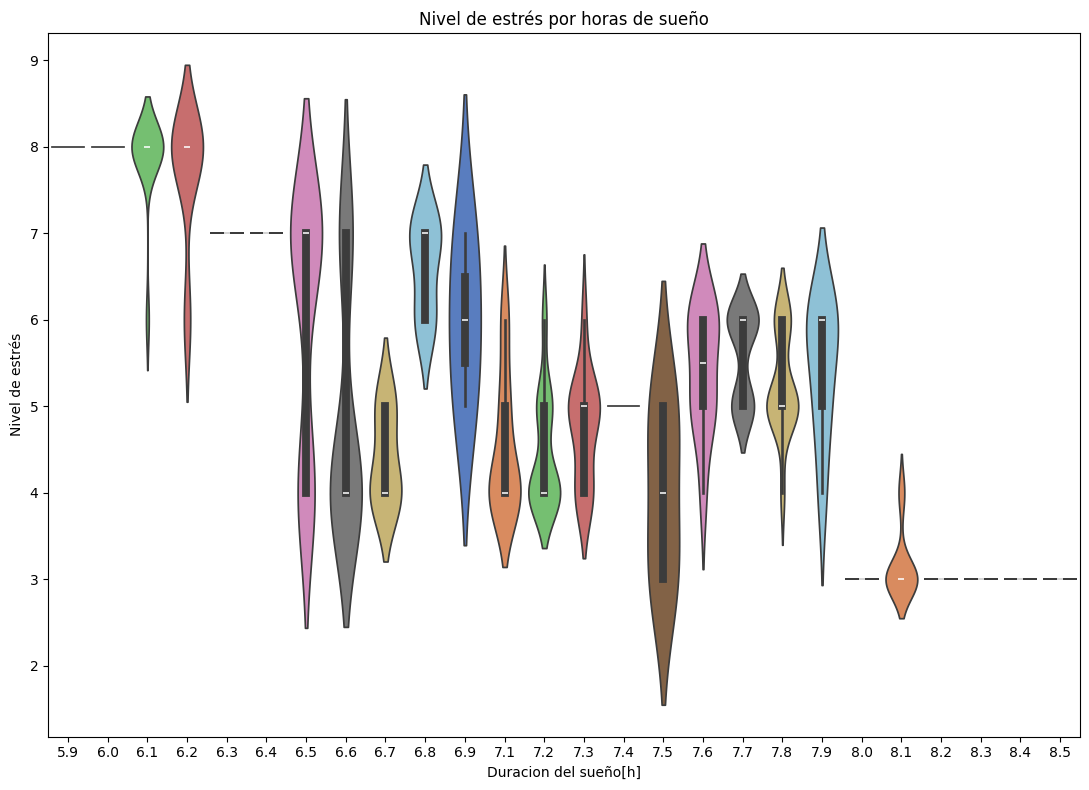

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11,8))

ejes = sns.violinplot(data=df, y="Stress Level", x="Sleep Duration", inner="box", legend=False, palette="muted")

ejes.set_title("Nivel de estrés por horas de sueño")
ejes.set_xlabel("Duracion del sueño[h]")
ejes.set_ylabel("Nivel de estrés")
plt.tight_layout()

plt.show()

Como se puede observar en el gráfico, a mayor nivel de estrés, la duración del sueño tiende a disminuir. Por lo cual, las personas con niveles de estrés alto o medio tienen más dificultades para descansar bien, lo que afecta la duración de su sueño. Las personas con estrés bajo tienen una mejor calidad de sueño y, generalmente, duermen más horas.

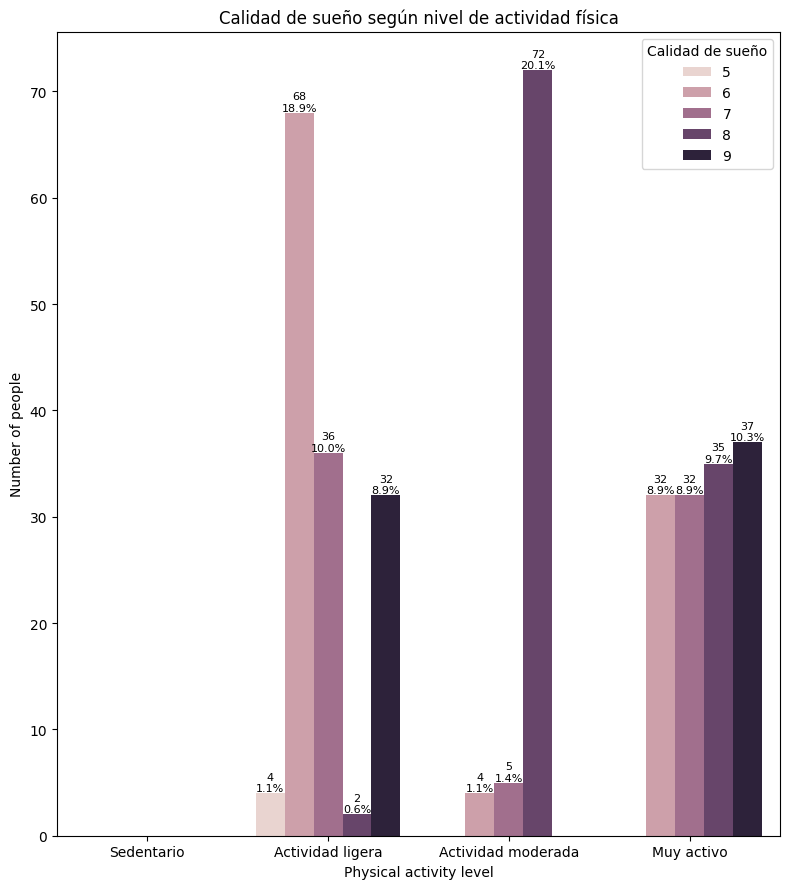

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_clean.csv")
# Esto categoriza los niveles de actividad física en 4 secciones (código reutilizado de gráfico anterior)
df["Nivel de Actividad"] = pd.cut(df["Physical Activity Level"], bins=[0, 25, 50, 75, float("inf")], labels=["Sedentario", "Actividad ligera", "Actividad moderada", "Muy activo"],right=False)
plt.figure(figsize=(8, 9))
df["Calidad de sueño"] = df["Quality of Sleep"]
ejes = sns.countplot(data=df, x="Nivel de Actividad", hue="Calidad de sueño")
ejes.set_title("Calidad de sueño según nivel de actividad física")
ejes.set_xlabel("Physical activity level")
ejes.set_ylabel("Number of people")
nombresEnEje(ejes, total)
plt.tight_layout()
plt.show()

El gráfico muestra cómo la calidad del sueño varía según el nivel de actividad física que realiza una persona. Como podemos observar, las personas con actividad física moderada y muy activa tienden a tener una mejor calidad del sueño.

Finalmente, analizando los gráficos llegamos a la conclusión de elegir las siguientes variables para la investigación:

[Principales]
*   Quality of Sleep.
*   Sleep Duration.

[Secundarias]
*   Physical activity level.
*   Stress Level.

Y la siguiente hipótesis:

¿Cómo influye el nivel de estrés y la actividad física en la calidad y duración del sueño?

# Entrega 2
1. Simulación:

###Heart Rate

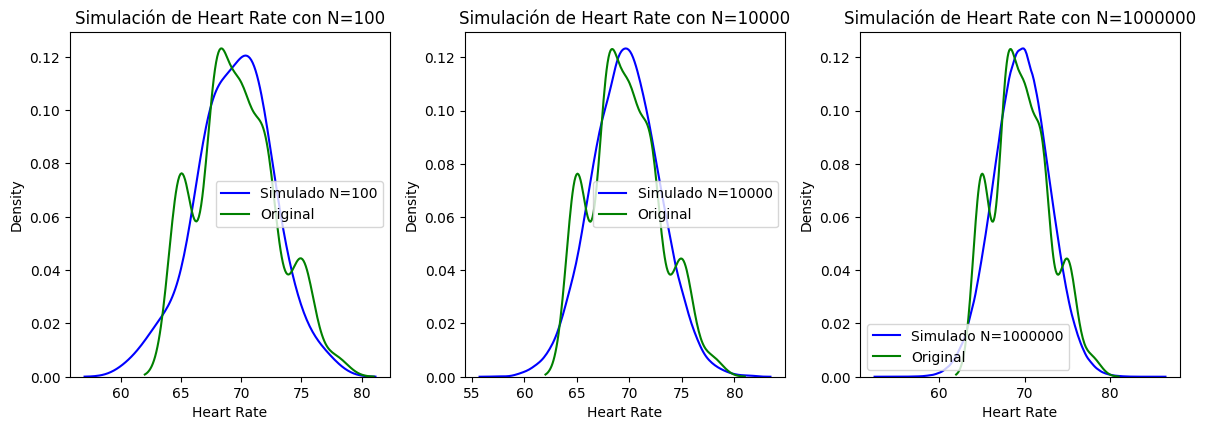

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, expon

df = pd.read_csv("dataset_clean.csv")
# Parámetros de las distribuciones de las variables
mean_heart_rate = df['Heart Rate'].mean()
std_heart_rate = df['Heart Rate'].std()

mean_duration = df['Sleep Duration'].mean()
std_duration = df['Sleep Duration'].std()

# Número de simulaciones
simulations = [10**2, 10**4, 10**6]

# Función para aplicar la transformación inversa
def inverse_transform_simulation(dist_params, dist_type, n_simulations):
    # Generar una variable uniforme U
    U = np.random.rand(n_simulations)

    if dist_type == 'normal':
        # Transformación inversa para la distribución normal
        return norm.ppf(U, loc=dist_params[0], scale=dist_params[1])


# Graficar las distribuciones comparadas
plt.figure(figsize=(12, 8))

for n in simulations:
    # Generar las muestras simuladas para Heart Rate.
    simulated_heart_rate = inverse_transform_simulation((mean_heart_rate, std_heart_rate), 'normal', n)

    # Graficar la distribución KDE
    plt.subplot(2, 3, simulations.index(n) + 1)
    sns.kdeplot(simulated_heart_rate, color='blue', label=f"Simulado N={n}")
    sns.kdeplot(df['Heart Rate'], color='green', label="Original")
    plt.legend()
    plt.title(f"Simulación de Heart Rate con N={n}")

plt.tight_layout()
plt.show()



# Sleep Duration

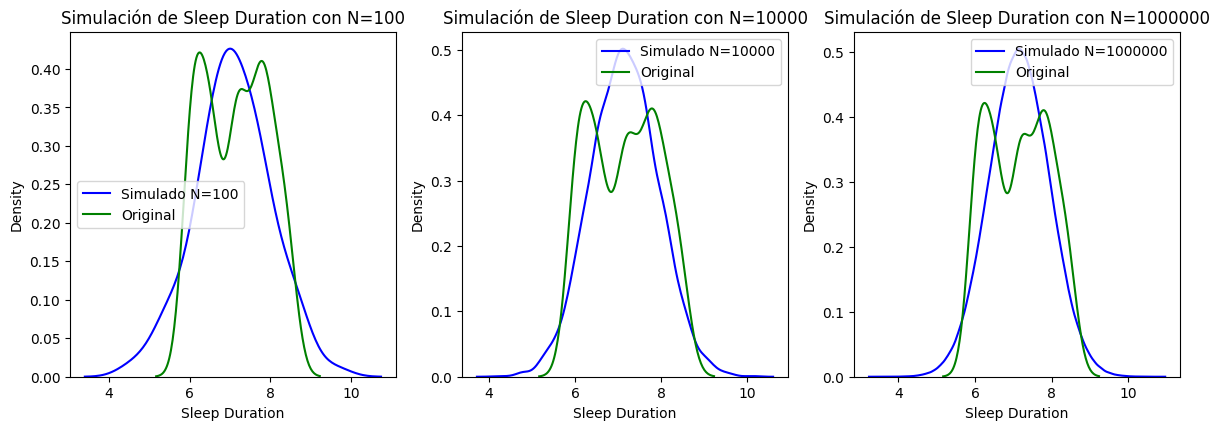

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, expon

df = pd.read_csv("dataset_clean.csv")

# Parámetros de las distribuciones de las variables
mean_quality = df['Quality of Sleep'].mean()
std_quality = df['Quality of Sleep'].std()

mean_duration = df['Sleep Duration'].mean()
std_duration = df['Sleep Duration'].std()

# Número de simulaciones
simulations = [10**2, 10**4, 10**6]

# Función para aplicar la transformación inversa
def inverse_transform_simulation(dist_params, dist_type, n_simulations):
    # Generar una variable uniforme U
    U = np.random.rand(n_simulations)

    if dist_type == 'normal':
        # Transformación inversa para la distribución normal
        return norm.ppf(U, loc=dist_params[0], scale=dist_params[1])


# Graficar las distribuciones comparadas
plt.figure(figsize=(12, 8))

for n in simulations:
    # Generar las muestras simuladas para Sleep Duration.
    simulated_quality = inverse_transform_simulation((mean_duration, std_duration), 'normal', n)

    # Graficar la distribución KDE
    plt.subplot(2, 3, simulations.index(n) + 1)
    sns.kdeplot(simulated_quality, color='blue', label=f"Simulado N={n}")
    sns.kdeplot(df['Sleep Duration'], color='green', label="Original")
    plt.legend()
    plt.title(f"Simulación de Sleep Duration con N={n}")

plt.tight_layout()
plt.show()


Análisis de Normalidad:

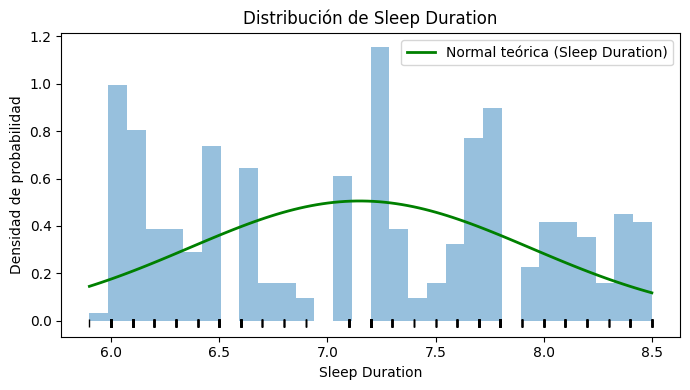

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("dataset_clean.csv")
# Datos de Heart Rate y Sleep Duration
heart_rate = df['Heart Rate']
sleep_duration = df['Sleep Duration']

# Histograma + curva normal teórica para Sleep Duration
# ==============================================================================

# Valores de la media (mu) y desviación típica (sigma) para Sleep Duration
mu_duration, sigma_duration = stats.norm.fit(sleep_duration)

# Valores teóricos de la normal en el rango observado
x_hat_duration = np.linspace(min(sleep_duration), max(sleep_duration), num=100)
y_hat_duration = stats.norm.pdf(x_hat_duration, mu_duration, sigma_duration)

# Gráfico para Sleep Duration
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(x_hat_duration, y_hat_duration, linewidth=2, label='Normal teórica (Sleep Duration)', color='green')
ax.hist(sleep_duration, density=True, bins=30, color="#3182bd", alpha=0.5)
ax.plot(sleep_duration, np.full_like(sleep_duration, -0.01), '|k', markeredgewidth=1)
ax.set_title('Distribución de Sleep Duration')
ax.set_xlabel('Sleep Duration')
ax.set_ylabel('Densidad de probabilidad')
ax.legend()

plt.tight_layout()
plt.show()


# Comprobacion para Sleep Duration

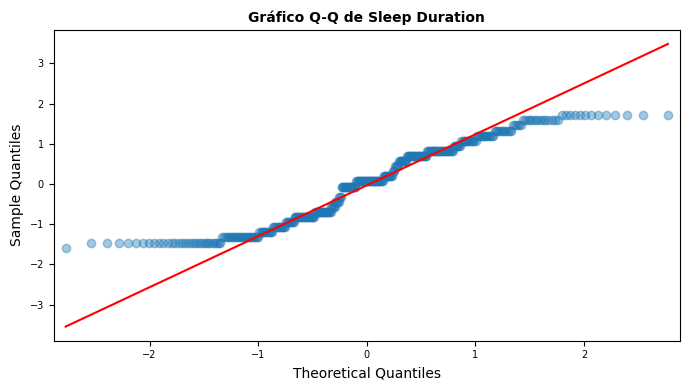

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Gráfico Q-Q para Sleep Duration
# ==============================================================================
df = pd.read_csv("dataset_clean.csv")
fig, ax = plt.subplots(figsize=(7,4))
sm.qqplot(
    sleep_duration,
    fit=True,
    line='q',
    alpha=0.4,
    lw=2,
    ax=ax
)
ax.set_title('Gráfico Q-Q de Sleep Duration', fontsize=10, fontweight="bold")
ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()



# Parámetros según el método de los momentos.

In [ ]:
import numpy as np


def momentos(data):
    n = len(data)

    primer_momento  = np.mean(data)
    segundo_momento  = np.mean(data**2)
    varianza = segundo_momento - primer_momento**2
    desviación  = np.sqrt(varianza)

    return primer_momento, segundo_momento, varianza, desviación

media_heart, segundo_momento_heart, var_heart, desvest_heart = momentos(df['Heart Rate'].dropna().values)
media_sleep, segundo_momento_sleep, var_sleep, desvest_sleep = momentos(df['Sleep Duration'].dropna().values)


print("   Variables       n       μ̂ MM         σ̂²MM        Var(x)     σ̂")
print("Heart Rate       ", len(heart_rate), "   ", round(media_heart, 4), "    ", round(segundo_momento_heart, 4), " ", round(var_heart,4), " ", round(desvest_heart, 4))
print("Sleep Duration   ", len(sleep_duration), "    ", round(media_sleep, 4), "    " , round(segundo_momento_sleep, 4),"    ", round(var_sleep, 3), "  ", round(desvest_sleep, 4))

   Variables       n       μ̂ MM         σ̂²MM        Var(x)     σ̂
Heart Rate        359     69.6295      4858.6825   10.4115   3.2267
Sleep Duration    359      7.1496      51.7404      0.624    0.7898


**Estimación por el Método de los Momentos Distribución Normal:**

Para la Distribución Normal:
$$
E[X] = \mu_{MM} = \frac{1}{n} \sum x_i
$$
$$
E[X^2] = \hat\sigma^{2}_{MM} = \frac{1}{n} \sum x_i^2
$$
$$
Var[X] = E[X^2] - (E[X])^2
$$


\begin{array}{|c|c|c|c|c|c|}
\hline
\text{Variable} & n & \hat\mu_{MM} & \hat\sigma^2_{MM} & Var[X] & \sigma \\
\hline
\text{Heart Rate}     & 359 & 69.6295 & 4858.6825 & 10.4115 & 3.2267 \\
\text{Sleep Duration} & 359 &  7.1496 &   51.7404 &  0.624 & 0.7898 \\
\hline
\end{array}



# Estimación de parámetros para la distribución normal

##Consideramos que los datos siguen una distribución normal, para la cual queremos estimar los parámetros.


### Función de Verosimilitud para la Distribución Normal

Para calcular los parámetros por el método de máxima verosimilitud, utilizamos la definición de la función de verosimilitud:

$$
f(\mu, \sigma) = \frac{1}{\sqrt{2 \pi \sigma^2}} \exp \left( -\frac{(x_i - \mu)^2}{2 \sigma^2} \right)
$$

\\
$$
L(\theta_1, \theta_2) = \prod_{i=1}^{n} \frac{1}{\sqrt{2 \pi \theta_2}}\cdot e^{-\frac{(x_i - \theta_1)^2}{2 \theta_2}}
$$

$$
L(\theta_1, \theta_2) = \left( \frac{1}{\sqrt{2 \pi \theta_2}} \right)^n\cdot e^{-\frac{\sum_{i=1}^{n} (x_i - \theta_1)^2} {2 \theta_2}}
$$
### Función Log-Verosimilitud.
$$
l(\theta_1, \theta_2) = ln\left( \frac{1}{\sqrt{2 \pi \theta_2}} \right)^n + \left( {-\frac{\sum_{i=1}^{n} (x_i - \theta_1)^2} {2 \theta_2}}\right)
$$


$$
= n \cdot ln\left( \frac{1}{\sqrt{2 \pi \theta_2}} \right)  {-\frac{1} {2 \theta_2}} \sum_{i=1}^{n} (x_i - \theta_1)^2
$$

$$
=- n \cdot \ln \left[ (2 \pi \theta_1)^{-1/2} \right] - \frac{1}{2 \theta_2} \sum_{i=1}^{n} (x_i - \theta_2)^2
$$

$$
= - \frac{n}{2} \ln(2 \pi) - \frac{n}{2} \ln(\theta_2) - \frac{1}{2 \theta_2} \sum_{i=1}^{n} (x_i - \theta_1)^2
$$

### Derivada parcial para $θ_1$:

$$
\frac{\partial \ell}{\partial \theta_1} = \frac{1}{2 \theta_2} \sum_{i=1}^{n} \left[ -2 (x_i - \theta_1) \right]
$$

$$
= \frac{1}{\theta_2} \sum_{i=1}^{n} (x_i - \theta_1)
$$

### Maximizamos:
$$
 \frac{1}{\theta_2} \sum_{i=1}^{n} (x_i - \theta_1) = 0
$$

$$
\Rightarrow \frac{1}{\theta_2} \sum_{i=1}^{n} (x_i - \theta_1) = 0 / \cdot \theta_2 \Rightarrow \sum_{i=1}^{n} (x_i - \theta_1) = 0
$$

$$
\Rightarrow - n \theta_1 + \sum_{i=1}^{n} x_i = 0 \Rightarrow \frac{1}{n} \sum_{i=1}^{n} x_i = \hat{\theta_1}
$$
$$
 \mu = \hat{\theta_1}
$$
### Concluyendo asi que el promedio $(μ)$ es nuestro parámetro $θ_1$.
### Ahora para $θ_2$:
$$
\frac{\partial \ell}{\partial \theta_2} = -\frac{n}{2 \theta_2^2} + \frac{1}{2 \theta_2^2} \sum_{i=1}^{n} (x_i - \theta_1)^2
$$

$$
\Rightarrow - \frac{n}{2 \theta_2^2} + \frac{1}{2 \theta_2^2} \sum_{i=1}^{n} (x_i - \theta_1)^2 = 0 / \cdot 2\theta_2^2  \Rightarrow \frac{1}{n} \sum_{i=1}^{n} (x_i - \hat{\mu})^2 = \hat{\theta_2}
$$
$$
\Rightarrow \frac{1}{n} \sum_{i=1}^{n} (x_i - {\mu})^2 = \hat{\theta_2}
$$
$$
\Rightarrow \sigma^2 = \hat{\theta_2}
$$

### Concluyendo asi que la varianza $(σ^2)$ es nuestro parámetro $θ_2$.

###Fórmulas finales para cada variable:
Para **Heart Rate**:
$$
f(x; 69.6295, 10.4115) = \frac{1}{\sqrt{2 \pi \cdot 10.4115}} \exp \left( -\frac{(x - 69.6295)^2}{2 \cdot 10.4115} \right)
$$
\
Para **Sleep Duration**:
$$
f(x; 7.1496, 0.624) = \frac{1}{\sqrt{2 \pi \cdot 0.624}} \exp \left( -\frac{(x - 7.1496)^2}{2 \cdot 0.624} \right)
$$


###Gráficos de la Distribución Empírica, la FDP mediante Método de los Momentos y Máxima Verosimilitud.

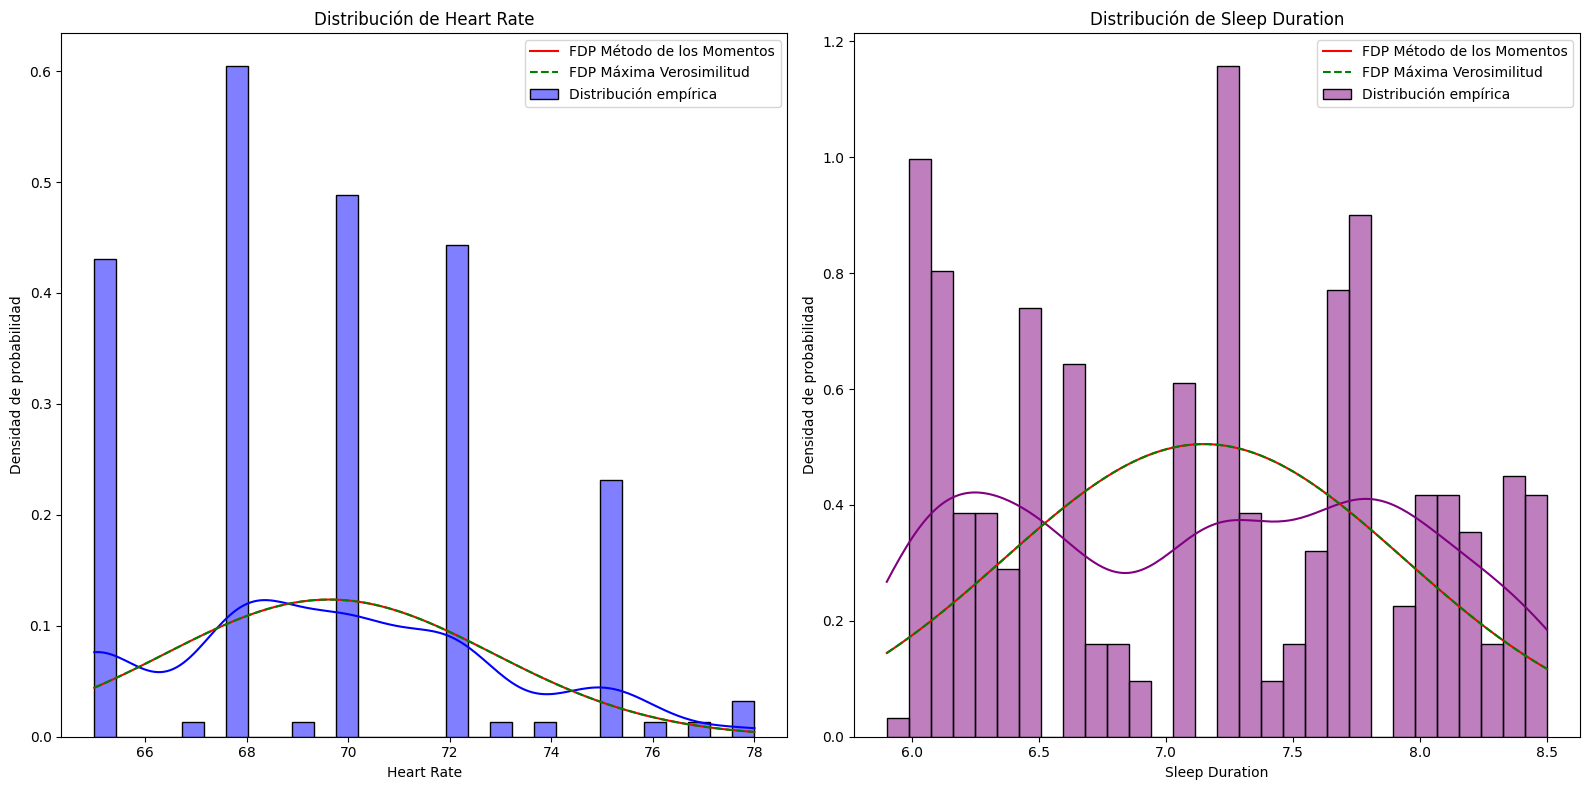

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

df = pd.read_csv("dataset_clean.csv")

# Variables
heart_rate = df['Heart Rate'].dropna().values
sleep_duration = df['Sleep Duration'].dropna().values

# Parámetros del Método de los Momentos para Heart Rate
mu_heart_rate_mm = np.mean(heart_rate)
sigma_heart_rate_mm = np.std(heart_rate)

# Parámetros del Método de Máxima Verosimilitud para Heart Rate
mu_heart_rate_mle, sigma_heart_rate_mle = norm.fit(heart_rate)

# Parámetros del Método de los Momentos para Sleep Duration
mu_sleep_duration_mm = np.mean(sleep_duration)
sigma_sleep_duration_mm = np.std(sleep_duration)

# Parámetros del Método de Máxima Verosimilitud para Sleep Duration
mu_sleep_duration_mle, sigma_sleep_duration_mle = norm.fit(sleep_duration)

# Crear los gráficos
plt.figure(figsize=(16, 8))

# Grafica para Heart Rate (1er gráfico)
plt.subplot(1, 2, 1)
sns.histplot(heart_rate, kde=True, color='blue', stat="density", bins=30, label="Distribución empírica")
x_vals_heart_rate = np.linspace(min(heart_rate), max(heart_rate), 100)

# FDP Método de los Momentos para Heart Rate
y_vals_heart_rate_mm = norm.pdf(x_vals_heart_rate, mu_heart_rate_mm, sigma_heart_rate_mm)
plt.plot(x_vals_heart_rate, y_vals_heart_rate_mm, 'r-', label="FDP Método de los Momentos")

# FDP Máxima Verosimilitud para Heart Rate
y_vals_heart_rate_mle = norm.pdf(x_vals_heart_rate, mu_heart_rate_mle, sigma_heart_rate_mle)
plt.plot(x_vals_heart_rate, y_vals_heart_rate_mle, 'g--', label="FDP Máxima Verosimilitud")

plt.title('Distribución de Heart Rate')
plt.xlabel('Heart Rate')
plt.ylabel('Densidad de probabilidad')
plt.legend()

# Grafica para Sleep Duration (2do gráfico)
plt.subplot(1, 2, 2)
sns.histplot(sleep_duration, kde=True, color='purple', stat="density", bins=30, label="Distribución empírica")
x_vals_sleep_duration = np.linspace(min(sleep_duration), max(sleep_duration), 100)

# FDP Método de los Momentos para Sleep Duration
y_vals_sleep_duration_mm = norm.pdf(x_vals_sleep_duration, mu_sleep_duration_mm, sigma_sleep_duration_mm)
plt.plot(x_vals_sleep_duration, y_vals_sleep_duration_mm, 'r-', label="FDP Método de los Momentos")

# FDP Máxima Verosimilitud para Sleep Duration
y_vals_sleep_duration_mle = norm.pdf(x_vals_sleep_duration, mu_sleep_duration_mle, sigma_sleep_duration_mle)
plt.plot(x_vals_sleep_duration, y_vals_sleep_duration_mle, 'g--', label="FDP Máxima Verosimilitud")

plt.title('Distribución de Sleep Duration')
plt.xlabel('Sleep Duration')
plt.ylabel('Densidad de probabilidad')
plt.legend()

# Ajustar el layout para que los gráficos no se sobrepongan
plt.tight_layout()

# Mostrar los gráficos
plt.show()


#5. Preguntas.
##1. ¿Qué suposiciones haces al usar cada método de estimación?
Para el Método de los Momentos, asumimos que los primeros dos momentos (media y varianza) de los datos son suficientes para estimar los parámetros de la distribución normal.

Para el Método de Máxima Verosimilitud se asume que la distribución de los datos es normal, y el objetivo es encontrar los parámetros (media y varianza) que maximizan la verosimilitud de los datos observados bajo esta distribución.
##2. ¿Cuáles son las limitaciones de los métodos de máxima verosimilitud y de los momentos en la práctica?

Las principales limitaciones para Método de los Momentos:

*   Si los datos no siguen una distribución normal o cualquier otra distribución conocida, los momentos no proporcionan un buen ajuste.
*   Es sensible a valores atípicos o outliers, lo que puede distorsionar la estimación de la media y la varianza.

Las principales limitaciones para Método de los Máxima Verosimilitud:


*   Para muestras pequeñas, los parámetros estimados pueden ser sesgados y no reflejar bien la verdadera distribución.
* En distribuciones complejas o con muchos parámetros, el cálculo de MLE suele ser computacionalmente costoso.

##3. ¿Cómo podrías aplicar el modelo ajustado para hacer predicciones o inferencias sobre una nueva muestra de datos?
* Para predicciones puntuales, se puede usar la distribución normal ajustada para obtener una estimación del valor esperado de la nueva muestra.
Por ejemplo, si estamos usando el modelo ajustado de distribución normal de "Heart Rate", podemos calcular la probabilidad de que el próximo valor de Heart Rate esté dentro de un intervalo específico.

##4. ¿Qué implicaciones tienen los parámetros estimados en el contexto del problema real que modela el dataset?
* Para "Heart Rate", obtuvimos una media de 70.1658 y varianza 17.058, lo cual significa un ritmo cardíaco promedio dentro de rangos saludables, con varianza pequeña entre individuos, lo que puede reflejar distintos niveles de actividad física, estrés o condiciones médicas.

* Para "Sleep Duration", la media fue 7.1321 horas y la varianza 0.631, lo que indica que la mayoría de las personas duerme entre 6 y 8 horas.  Esto sugiere una mayor regularidad en los hábitos de sueño de los individuos estudiados.


##5. ¿De qué forma se puede validar los resultados que no sea de forma gráfica?
* Podemos utilizar otras herramientas además de la gráfica para verificar si los resultados de las estimaciones se adecuan a los datos reales.
  * Error cuadrático medio (MSE): Podemos calcular el MSE, el cual es una medida que nos indica qué tan bien se adecua la la distribución teórica a los datos observados. Si el MSE es pequeño (tiende a 0), el ajuste de la distribución estimada es muy acertada. Mientras que si es un valor grande existe una diferencia importante entre lo que predice el modelo y lo que se observa en los datos.
  * Intervalos de confianza: Podemos calcular intervalos de confianza para la media y la varianza, para luego comparar con las estimaciones que obtuvimos anteriormente y determinar si se encuentran en un rango razonable para la situación.
  * Además, podemos ocupar un modelo analitico de asimetria(skewness), como se muestra a continuación:


In [ ]:
import pandas as pd
from scipy.stats import skew

#Cargar el dataset
df = pd.read_csv('dataset_clean.csv')

#Calcular asimetría para 'Sleep Duration'
sleep_duration_skewness = skew(df['Sleep Duration'])

#Calcular asimetría para 'Heart Rate'
heart_rate_skewness = skew(df['Heart Rate'])

#Verificar si están dentro del rango de normalidad
sleep_duration_normality = -1 <= sleep_duration_skewness <= 1
heart_rate_normality = -1 <= heart_rate_skewness <= 1

#Imprimir resultados
print(f"Sleep Duration - Skewness: {sleep_duration_skewness}, Desviación de normalidad: {sleep_duration_normality}")
print(f"Heart Rate - Skewness: {heart_rate_skewness}, Desviación de normalidad: {heart_rate_normality}")

Sleep Duration - Skewness: 0.028669671275021662, Desviación de normalidad: True
Heart Rate - Skewness: 0.3234900440319126, Desviación de normalidad: True


#Entrega 3
##Comprobación



###Intervalo de Confianza para la variable Hear Rate:
Para el cálculo de un intervalo de confianza de una muestra de datos, teniendo en cuenta que esta se distribuye como una Normal, además sabiendo que su parametro μ = E[x], pero su varianza es desconocida. Debemos utilizar la distribución T-Student, con la que se obtiene la siguiente formula para el IC:

$$
\left[ \bar{X} - t^{n-1}_{\alpha/2} \cdot \frac{S}{\sqrt{n}},\; \bar{X} + t^{n-1}_{\alpha/2} \cdot \frac{S}{\sqrt{n}} \right]
$$

Los datos utilizados son:

* ( X̄ ): Media muestral.
* ( S ): Desviación estándar muestral.
* ( n ): Tamaño de la muestra.
* ( t ): Valor de la acumulada inversa de la distribución de T-Student

Pero para este caso, dado que la cantidad de datos ( n ) es mucho mayor a 50. La T-Student es prácticamente indistinguible de la Normal Estándar. Entonces debido a esa razón, para determinar los Intervalos de Confianza de ambas variables lo haremos con la Normal Estándar.

In [ ]:
heart_rates = df["Heart Rate"]
sleep_duration = df["Sleep Duration"]

n1 = len(heart_rates) # Cantidad de datos
n2 = len(sleep_duration) # Cantidad de datos

print("Tamaño muestral de columna Heat Rate:", n1)
print("Tamaño muestral de columna Sleep Duration:", n2)

Tamaño muestral de columna Heat Rate: 359
Tamaño muestral de columna Sleep Duration: 359


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

heart_rates = df["Heart Rate"]

n = len(heart_rates) # Cantidad de datos
media = np.mean(heart_rates) # Media aritmetica
desv_std = np.std(heart_rates, ddof=1)  # Desviación estándar muestral

# Nivel de confianza: 97.8%
alpha = 0.022
z = norm.ppf(1 - alpha / 2)  # Valor crítico de z para 97.8% de confianza

# Cálculo del margen de error
margen_error = z * (desv_std / np.sqrt(n))

# Cálculo del intervalo de confianza
IC = (media - margen_error, media + margen_error)

# Resultado
print(f"Intervalo de confianza del 97.8% para la media de Heart Rate: {IC}")

Intervalo de confianza del 97.8% para la media de Heart Rate: (np.float64(69.23893720314658), np.float64(70.02011572164452))


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

sleep_duration = df["Sleep Duration"]

n = len(sleep_duration) # Cantidad de datos
media = np.mean(sleep_duration) # Media aritmetica
desv_std = np.std(sleep_duration, ddof=1)  # Desviación estándar muestral

# Nivel de confianza: 97.8%
alpha = 0.022
z = norm.ppf(1 - alpha / 2)  # Valor crítico de z para 97.8% de confianza

# Cálculo del margen de error
margen_error = z * (desv_std / np.sqrt(n))

# Cálculo del intervalo de confianza
IC = (media - margen_error, media + margen_error)

# Resultado
print(f"Intervalo de confianza del 97.8% para la media de Sleep Duration: {IC}")

Intervalo de confianza del 97.8% para la media de Sleep Duration: (np.float64(7.0539730680483785), np.float64(7.24519127735552))


Entonces desarrollando los cálculos con la Normal Estándar, obtenemos que los Intervalos de Confianza para μ de ambas variables son (aproximadamente):
* Heart Rate: (69.2389, 70.0201)
* Sleep Duration: (7.0540, 7.2452)

En los que podemos notar que son margenes bastantes cercanos a las medias entregadas por el método de los momentos hecho anteriormente.

Dado que se está utilzando la distribución Normal Estándar debido a las razones ya explicadas, la Incertidumbre de un intervalo viene dado por la expresión:

$$
z_{\alpha/2} \cdot \frac{S}{\sqrt{n}}
$$

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

heart_rates = df["Heart Rate"]

n = len(heart_rates)
media = np.mean(heart_rates)
desv_std = np.std(heart_rates, ddof=1)
alpha = 0.022
z = norm.ppf(1 - alpha / 2)

# Cálculo del margen de error
incertidumbre = z * (desv_std / np.sqrt(n))

print("Incertidumbre de Heart Rate:", incertidumbre)

Incertidumbre de Heart Rate: 0.3905892592489699


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm

sleep_duration = df["Sleep Duration"]

n = len(sleep_duration)
media = np.mean(sleep_duration)
desv_std = np.std(sleep_duration, ddof=1)
alpha = 0.022
z = norm.ppf(1 - alpha / 2)

# Cálculo del margen de error
incertidumbre = z * (desv_std / np.sqrt(n))

print("Incertidumbre de Sleep Duration:", incertidumbre)

Incertidumbre de Sleep Duration: 0.09560910465357049


Entonces sabemos que nuestros niveles de incertidumbre son:
* Heart Rate: 0.3906
* Sleep Duration: 0.0956

Ahora debemos determinar cuantos datos más se necesitan para que nuestros niveles de incertidumbre desciendan un 76%.

Para esto, sabemos que el nivel de incertidumbre viene dado por:

$$
U = z_{\alpha/2} \cdot \frac{S}{\sqrt{n}}
$$

Y para reducir este valor un 76% entonces:

$$
U_{\text{nuevo}} = 0.24 \cdot U
$$

De estas expresiónes podemos observar que la incertidumbre es **inversamente proporcional** a la raíz cuadrada del tamaño muestral.

$$
U \propto \frac{1}{\sqrt{n}} \quad \Rightarrow \quad
U_{\text{nuevo}} = z_{\alpha/2} \cdot \frac{S}{\sqrt{n'}}
$$

Siendo n' los datos necesarios para que se disminya un 76% la incertidumbre.

Por lo tanto:

$$
\frac{1}{\sqrt{n'}} = 0.24 \cdot \frac{1}{\sqrt{n}} \Rightarrow
\sqrt{n'} = \frac{1}{0.24} \cdot \sqrt{n}
$$

De esta manera, despejando **n'** y teniendo en cuenta que nuestras muestas originales tienen un tamaño de **359 datos**.

$$
n' \approx 17.36 \cdot 359 \approx 6233
$$

Entonces, se necesitan aproximadamente **6233 datos** para lograr una reducción del 76% en la incertidumbre.  
Por lo tanto, **faltan**:

$$
6233 - 359 = 5874 \text{ datos adicionales.}
$$

Ahora queremos reducir el nivel de incertidumbre en un 76% pero variando el nivel de significancia. Entonces sabemos que actualmente trabajamos con un **nivel de confianza del 97.8%**, es decir:

$$
\alpha = 1 - 0.978 = 0.022
\Rightarrow z_{\alpha/2} = z_{0.011} \approx 2.29
$$

Y estamos buscando reducir la incertidumbre en un **76%**, por lo que necesitamos:

$$
z_{\alpha/2}^{\text{nuevo}} = 0.24 \cdot 2.29 \approx 0.5496
$$

Para encontrar el nuevo nivel de confianza, buscamos este resultado acumulado en la tabla de la distribución Normal Estándar.

$$
\Phi(0.5496) \approx 0.7084
\Rightarrow \frac{\alpha}{2} = 1 - 0.7084 = 0.2916
\Rightarrow \alpha = 2 \cdot 0.2916 = 0.5832
$$

Entonces, para lograr la reducción del 76% en la incertidumbre sin cambiar el tamaño de muestra, se debe usar:

$$
\alpha \approx 0.5832 \Rightarrow \text{Nivel de confianza} \approx 41.68\%
$$


## Comparación

Si se comparan estos dos métodos de reducir el nivel de incertidumbre, se puede determinar que es mucho más factible el primer método que el segundo.
Ya que, en cuanto al nivel de significancia, este es muy bajo para ser aceptable en la práctica, por lo que es más razonable aumentar el tamaño muestral si se desea mayor precisión sin perder confiabilidad estadística.

#BONUS

In [ ]:
from scipy.stats import norm, t
import math

def analizar_reduccion_incertidumbre(reduccion, n, alpha):
    # Determinar distribución usada según tamaño muestral
    if n_actual < 50:
        distribucion = "t-student"
        grados_libertad = n_actual - 1
        valor_critico_actual = t.ppf(1 - alpha_actual / 2, df=grados_libertad)
    else:
        distribucion = "normal"
        valor_critico_actual = norm.ppf(1 - alpha_actual / 2)

    # 1. Calcular nuevo n necesario para alcanzar la reducción
    factor = 1 / (1 - reduccion)
    nuevo_n = math.ceil((factor ** 2) * n_actual)

    # 2. Calcular nuevo alpha si n es fijo
    valor_critico_nuevo = (1 - reduccion) * valor_critico_actual

    # Buscar el nuevo alpha según la distribución usada
    if distribucion == "t-student":
        # Necesitamos iterar para encontrar alpha tal que t.ppf(1 - alpha/2, df=n-1) ≈ valor_critico_nuevo
        # Usamos el inverso de la función acumulada para encontrarlo
        prob_acumulada = t.cdf(valor_critico_nuevo, df=grados_libertad)
    else:
        prob_acumulada = norm.cdf(valor_critico_nuevo)

    nuevo_alpha = 2 * (1 - prob_acumulada)

    return nuevo_n, nuevo_alpha


n_actual = int(input("Ingrese el tamaño muestral: ")) # Tamaño muestral
alpha_actual = float(input("Ingrese el nivel de confianza actual: ")) # Alpha directamente, no porcentaje
reduccion = float(input("Ingrese la reducción de incertidumbre deseada: ")) # Nivel de reducción en float, no porcentaje. EJ: 76% entonces se debe escribir 0.76


print(analizar_reduccion_incertidumbre(reduccion, n_actual, alpha_actual))

Ingrese el tamaño muestral: 359
Ingrese el nivel de confianza actual: 0.05
Ingrese la reducción de incertidumbre deseada: 0.76
(6233, np.float64(0.6380754385298928))


#Parte 2. Realizar una prueba de bondad de ajuste para las 2 variables con sus distribuciones escogidas.

Al momento de realizar una prueba de Kolmogorov-Smirnov comparamos la distribución empírica de nuestros datos con una distribución teórica especificada, en este caso una normal.

Utilizamos la prueba de Kolmogorov-Smirnov (KS) porque:

Es flexible: Permite comparar los datos con una distribución teórica continua específica, como la normal, en este caso.

No requiere agrupar los datos: A diferencia de otras pruebas, no necesitamos dividir los datos en intervalos, lo que la hace adecuada para datos continuos.

Trabajamos con un nivel de significancia estándar de α=0.05 (5%). Ya que si trabajamos con un nivel mayor aumenta la probabilidad de rechazar incorrectamente la hipotesis nula (Esto significa que podríamos concluir que los datos no siguen la normal cuando en realidad sí lo hacen.)

In [ ]:
from scipy import stats

# Test de Kolmogorov-Smirnov para verificar si la distribución es normal para Heart Rate
ks_stat, ks_p_value = stats.kstest(df['Heart Rate'], 'norm', args=(df['Heart Rate'].mean(), df['Heart Rate'].std()))

print(f"Kolmogorov-Smirnov Test para Heart Rate: estadístico = {ks_stat}, p-valor = {ks_p_value}")


Kolmogorov-Smirnov Test para Heart Rate: estadístico = 0.16037204262775817, p-valor = 7.176557585568187e-09


In [ ]:
# Test de Kolmogorov-Smirnov para verificar si la distribución es normal para Sleep Duration
ks_stat_sleep, ks_p_value_sleep = stats.kstest(df['Sleep Duration'], 'norm', args=(df['Sleep Duration'].mean(), df['Sleep Duration'].std()))

print(f"Kolmogorov-Smirnov Test para Sleep Duration: estadístico = {ks_stat_sleep}, p-valor = {ks_p_value_sleep}")


Kolmogorov-Smirnov Test para Sleep Duration: estadístico = 0.12784770095245895, p-valor = 8.666442443973268e-06


In [ ]:
from scipy import stats

# Test de normal para Heart Rate
ks_stat_heart_rate, ks_p_value_heart_rate = stats.kstest(df['Heart Rate'], 'norm', args=(df['Heart Rate'].mean(), df['Heart Rate'].std()))

print(f"Test KS para Heart Rate con distribución normal: estadístico = {ks_stat_heart_rate}, p-valor = {ks_p_value_heart_rate}")

# Test de exponencial para Heart Rate
ks_stat_heart_rate_exp, ks_p_value_heart_rate_exp = stats.kstest(df['Heart Rate'], 'expon', args=(df['Heart Rate'].min(), df['Heart Rate'].max() - df['Heart Rate'].min()))

print(f"Test KS para Heart Rate con distribución exponencial: estadístico = {ks_stat_heart_rate_exp}, p-valor = {ks_p_value_heart_rate_exp}")

print("\n")

# Test de normal para Sleep Duration
ks_stat_sleep, ks_p_value_sleep = stats.kstest(df['Sleep Duration'], 'norm', args=(df['Sleep Duration'].mean(), df['Sleep Duration'].std()))

print(f"Test KS para Sleep Duration con distribución normal: estadístico = {ks_stat_sleep}, p-valor = {ks_p_value_sleep}")

# Test de exponencial para Sleep Duration
ks_stat_sleep_exp, ks_p_value_sleep_exp = stats.kstest(df['Sleep Duration'], 'expon', args=(df['Sleep Duration'].min(), df['Sleep Duration'].max() - df['Sleep Duration'].min()))

print(f"Test KS para Sleep Duration con distribución exponencial: estadístico = {ks_stat_sleep_exp}, p-valor = {ks_p_value_sleep_exp}")




Test KS para Heart Rate con distribución normal: estadístico = 0.16037204262775817, p-valor = 7.176557585568187e-09
Test KS para Heart Rate con distribución exponencial: estadístico = 0.5569740346207991, p-valor = 9.743946684265977e-110


Test KS para Sleep Duration con distribución normal: estadístico = 0.12784770095245895, p-valor = 8.666442443973268e-06
Test KS para Sleep Duration con distribución exponencial: estadístico = 0.36787944117144233, p-valor = 6.707412896642962e-46


#Conclusión
Como podemos observar, el valor del estadístico para ambos resultados no es cercano a 0, lo que indica que los datos no siguen perfectamente la distribución teórica.

Sin embargo, el estadístico de la distribución normal es menor que el de la distribución exponencial, lo que sugiere que el ajuste de los datos a la distribución normal es mejor que el de la exponencial.

Además, en el inciso anterior, se comprobó que el promedio de los datos efectivamente pertenece al intervalo de confianza calculado bajo la suposición de normalidad. Esto refuerza la idea de que la distribución normal puede ser una aproximación razonable para modelar estos datos.

Aunque la prueba de Kolmogorov-Smirnov nos mostró que no hay un ajuste perfecto a ninguna de las distribuciones teóricas probadas, el hecho de que la normal haya mostrado el mejor ajuste (con un estadístico más bajo y p-value mas grande) refuerza la hipótesis de que los datos podrían seguir una distribución normal. Además, los resultados obtenidos, junto con el ajuste razonable del intervalo de confianza, brindan un respaldo adicional a la normalidad de los datos, especialmente en comparación con otras distribuciones, como la exponencial.

###Tema 8

3 )

El contraste que permite evaluar la hipótesis de "las medias de pulso cardíaco de enfermeros es distinto a las medias de pulso cardíaco de los doctores"
$$ H_0: \mu_1 = \mu_2$$
$$ H_1: \mu_1 \neq \mu_2$$

Siendo $\mu_1$ la media del pulso cardíaco del grupo 1 (enfermería) y $\mu_2$ la media del pulso cardíaco del grupo 2 (Doctores).

Trabajaremos con un nivel de significancia del 5%
Teniendo en cuenta:

$\bullet$ Los supuestos serán: Las variables (ocupacion y heart rate) son independientes, no conocemos las varianzas poblacionales, por lo que utilizaremos varianza muestral, las varianzas son distintas.

$\bullet$ Utilizaremos varianzas desconocidas, por lo que nos toca
ver los IC para las varianzas y ver si podemos asumir que son iguales o distintas.

$\bullet$ La variable que vamos a dividir en grupos es "Occupation", dividiremos esta variable en dos grupos dependiendo de la ocupación (Enfermería y Doctor)

Y el estadístico utilizado:
$$
t \;=\;
\frac{\bar{X}_1 \;-\; \bar{X}_2}
     {\sqrt{\displaystyle\frac{s_1^2}{n_1} \;+\; \frac{s_2^2}{n_2}}}
$$

Grados de libertad aproximados
$$
\nu \;\approx\;
\frac{\Bigl(\tfrac{s_1^2}{n_1} + \tfrac{s_2^2}{n_2}\Bigr)^2}
     {\displaystyle\frac{(s_1^2/n_1)^2}{\,n_1 - 1\,}
      \;+\;
      \frac{(s_2^2/n_2)^2}{\,n_2 - 1\,}}
$$

In [ ]:
import pandas as pd


# Carga de datos
df = pd.read_csv("dataset_clean.csv")
alpha = 0.05
# 2. Definir grupos según Sleep Duration
grupo1 = df[df["Occupation"] == "Nurse"]["Heart Rate"]
grupo2 = df[df["Occupation"] == "Doctor"]["Heart Rate"]


s1 = grupo1.std(ddof=1)
s2 = grupo2.std(ddof=1)

print(f"Desviación estándar del grupo 1: {round(s1,2)}")
print(f"Desviación estándar del grupo 2: {round(s2,2)}")

Desviación estándar del grupo 1: 3.57
Desviación estándar del grupo 2: 1.57


In [ ]:
from scipy.stats import f

# Entradas (puedes modificar estos valores)
alpha = 0.05
n1 = 71  # tamaño muestra 1
n2 = 67  # tamaño muestra 2
s1_sq = 3.57  # varianza muestra 1
s2_sq = 1.57  # varianza muestra 2

# Estadístico F (mayor varianza debe ir arriba)
if s1_sq > s2_sq:
    F = s1_sq / s2_sq
    df1 = n1 - 1
    df2 = n2 - 1
else:
    F = s2_sq / s1_sq
    df1 = n2 - 1
    df2 = n1 - 1

# p-valor bilateral
p_val = 2 * min(f.cdf(F, df1, df2), 1 - f.cdf(F, df1, df2))

f_inf = f.ppf(alpha / 2, df1, df2)
f_sup = f.ppf(1 - alpha / 2, df1, df2)

IC_inf = F / f_sup
IC_sup = F / f_inf

# Imprimir resultados
print(f"F = {F:.4f}")
print(f"Grados de libertad: ({df1}, {df2})")
print(f"Intervalo de confianza del {100*(1-alpha):.0f}% para sigma_1^2 / sigma_2^2:")
print(f"p-valor (bilateral) = {p_val:.6f}")
print(f"({IC_inf:.4f}, {IC_sup:.4f})")




F = 2.2739
Grados de libertad: (70, 66)
Intervalo de confianza del 95% para sigma_1^2 / sigma_2^2:
p-valor (bilateral) = 0.000925
(1.4052, 3.6670)


$$IC = [1.4052, 3.6670]$$

Como el 1 no pertenece al IC, no podemos asumir que las varianzas son iguales. Por lo que trabajaremos con el estadístico de diferencias de medias con varianzas desconocidas y distintas

In [ ]:
#seleccionamos 2 grupos segun la variable de tiempo de sueño, grupo 1: enfermeros, grupo 2: doctores, despues calculamos las medias muestrales,
#las cantidades de personas, las varianzas muestral.
# H0 = medias iguales
# H1 = medias distintas
#alpha = 0.05

import pandas as pd
import numpy as np
from scipy import stats

# Carga de datos
df = pd.read_csv("dataset_clean.csv")
alpha = 0.05
# 2. Definir grupos según Sleep Duration
grupo1 = df[df["Occupation"] == "Nurse"]["Heart Rate"]
grupo2 = df[df["Occupation"] == "Doctor"]["Heart Rate"]

# Estadísticos descriptivos
n1 = len(grupo1)
n2 = len(grupo2)
m1 = grupo1.mean()
m2 = grupo2.mean()
s1 = grupo1.std(ddof=1)
s2 = grupo2.std(ddof=1)

print("Grupo 1 (Enfermeria): n =", n1,"|", "media:", round(m1,2),"|", "desviacion estandar muestral:", round(s1,2))
print("Grupo 2 (Doctor): n =", n2,"|", "media:", round(m2,2),"|", "desviacion estandar muestral:", round(s2,2),"\n")

# Estadístico t, varianzas desconocidas y distintas
Z = (m1 - m2) / np.sqrt(s1**2/n1 + s2**2/n2)

# Grados de libertad
v = ((s1**2/n1 + s2**2/n2)**2/ ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1)))

#region de rechazo
t_sup = stats.t.ppf(1 - alpha/2, v)
t_inf = stats.t.ppf(alpha/2, v)
print(f"Región de rechazo bilateral:")
print(f" t < {t_inf:.4f}  o  t > {t_sup:.4f}")

# Cálculo del p-valor bilateral usando la CDF de Student
p_bilateral = 2 * (1 - stats.t.cdf(abs(Z), v))

print("t_v =", round(Z,2))
print("grados de libertad: ",round(v,2))
print("p-valor (bilateral) =", p_bilateral)

# Decisión
if p_bilateral < alpha:
    print("\nComo p < α, rechazamos H0: las medias difieren.")
else:
    print("\np >= α, no podemos rechazar H0: no hay evidencia de diferencia.")

Grupo 1 (Enfermeria): n = 71 | media: 71.77 | desviacion estandar muestral: 3.57
Grupo 2 (Doctor): n = 67 | media: 70.75 | desviacion estandar muestral: 1.57 

Región de rechazo bilateral:
 t < -1.9846  o  t > 1.9846
t_v = 2.21
grados de libertad:  97.35
p-valor (bilateral) = 0.029233483904415047

Como p < α, rechazamos H0: las medias difieren.


Rechazamos $H_{0}$, por lo que tenemos evidencia para pensar que las medias si difieren, si nuestra conclusion es incorrecta, estariamos cometiendo un error de tipo 1 (Rechazar $H_{0}$ siendo que es verdadera)

En el caso de haber trabajado con varianzas conocidas en vez de desconocidas, obtendriamos un intervalo mas estrecho, esto se debe a que cuando trabajamos con varianzas desconocidas, se considera la variabilidad de la estimacion de la varianza, osea, se hace mas grande el intervalo.

4.

Regresion lineal:

Variables a considerar, QUALITY OF SLEEP - STRESS LEVEL.

Para esto, hacemos la regresion lineal con ayuda de la libreria "statsmodels.api", especificamente usaremos la funcion OLS (minimos cuadrados perfectos/Ordinary least squares), que es una forma sencilla de regresion lineal.


                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.824
Method:                 Least Squares   F-statistic:                     1680.
Date:                Fri, 04 Jul 2025   Prob (F-statistic):          4.79e-137
Time:                        20:09:23   Log-Likelihood:                -239.07
No. Observations:                 359   AIC:                             482.1
Df Residuals:                     357   BIC:                             489.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           10.4726      0.080    131.626   

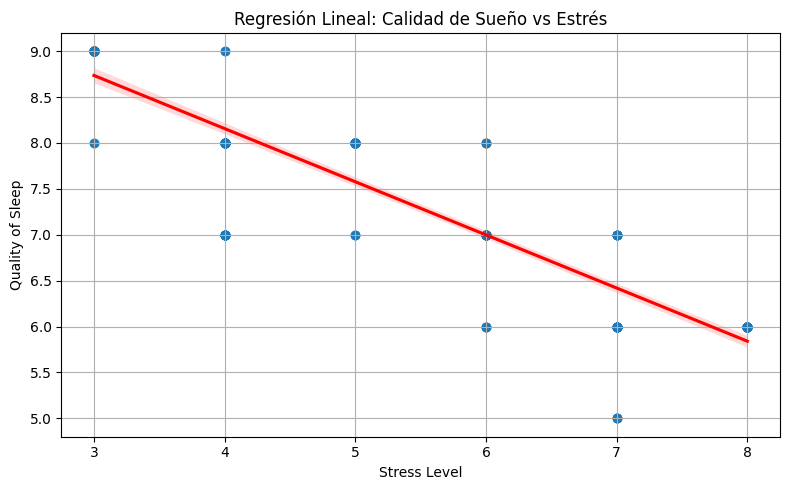

In [ ]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


df = pd.read_csv("dataset_clean.csv")


X = df["Stress Level"]
Y = df["Quality of Sleep"]


X_const = sm.add_constant(X)
modelo = sm.OLS(Y, X_const).fit()





print(modelo.summary())
a = modelo.params["Stress Level"]
b = modelo.params["const"]
r2 = modelo.rsquared

print(f"Modelo: Y = {b:.2f} + {a:.2f} * X")
print(f"R^2: {r2:.3f}")


plt.figure(figsize=(8, 5))
sns.regplot(x=X, y=Y, ci=95, line_kws={"color": "red"})
plt.xlabel("Stress Level")
plt.ylabel("Quality of Sleep")
plt.title("Regresión Lineal: Calidad de Sueño vs Estrés")
plt.grid(True)
plt.tight_layout()
plt.show()

Analizando los datos, vemos que tenemos una pendiente de -0,58, esto quiere decir que por cada "punto" de estres aumentado, la calidad del sueño disminuye en 0,58 "puntos" (en promedio), aparte de eso, el coeficiente de determinacion ($R^{2}$) nos da 0,825, osea un 82,5% de variacion de la calidad del sueño producto del nivel de estres, este valor alto, nos indica un buen ajuste.
